# Two fixes to the template-matching step, the ROI border band and a floor clip: 49 ROIs x 6 clicks, `mo_pad61`, post-D11

**Pre-registration.** This cell was written before any search ran, from `TM_BORDER_AND_FLOOR_PROMPT.md` (2026-10-01).
It fixes the arms, the mechanism checks, the families and the decision rule. Nothing below it changes it. The
reading of the results is the last cell. Every number is in-sample on the 49 ROIs of `images/extra_valid` (D5's
standing constraint).

## What is tested

The recorded search is `mo_pad61`: the multi-Otsu box of `c767898` (fixed 2 px margin), kept in a 61 px window whose
outside is filled with its own mean. It runs on `hematoxylin_od` with `cv2.TM_CCOEFF` (D1). The D11 blank is a 51 px
square at the click, filled with `channel.min()`. `MAX_PEAKS = 100` before NMS (D9), and NMS uses `ev.radius_px(mpp)`
(D7). Both ranking axes are kept (D5). Two mechanisms in that step make false positives:
1. **The ROI border.** The search channel is replicate-padded by 30 px, so a dark boundary pixel becomes a 30 px streak
   and the mass term scores it.
2. **The white surround.** The mass term is proportional to box mean minus ring mean. Glass is the lightest ring there
   is, and the D11 blank adds a local white patch next to the seed.

**Fix 1, border band out of the search.** Pixels within `pad = 30` px of the ROI edge are removed from the search.

**Fix 2, floor clip.** `hem_c = np.maximum(hem, b)` is used for the template, the blank and the search. Three things
stay on the unclipped `hem`:
- the refinement box;
- chromatin od, so the ranking axis is identical across arms;
- the white fraction.

The floor `b` is either:
- `b_otsu`, the lower threshold of `threshold_multiotsu(hem, classes=3)` over the whole ROI; or
- `b_med`, the ROI median.

**D1 and D3.** D1 holds, since the matcher stays `cv2.TM_CCOEFF`. The floor clip is admissible under D3 because it is
not a rescale, stretch or top clip. It changes only the bottom of the OD range. The darkest chromatin, which D3
protects from saturation, is untouched. Adopting the clip would still need a dated amendment to D3.

## One change to the prompt, made before this notebook was written, and why

**The spec version of fix 1 leaks.** The prompt sets `valid = False` in the band before `robust_stats` and
`extract_peaks`. But `extract_peaks` dilates the *whole* fused map and only then applies `valid`. A band response can
therefore still beat an interior pixel at `edge_px` 30 to 36 in the 15 x 15 max filter, and that interior pixel is no
longer a local maximum.

A scratch test (scratchpad `leak_test.py`, before any code here) ran the recorded `mo_pad61` templates, with the
band's scores floored before `extract_peaks`:
- **Uncapped:** 189 to 301 interior peaks came back per click, on all 18 clicks of `337.tiff`, `201.tiff` and
  `300.tiff`.
- **`201.tiff`:** the top-100 pre-NMS set and the post-NMS list changed on all 6 clicks.

The prompt's rule for a wrongly specified fix is to implement what the mechanism requires and keep the specified
version as an extra arm if it is cheap. So:
- **`A1` and `A3` floor the band.** `fused[band] = _FLOOR` before `extract_peaks`, and `valid` is False in the band.
  `robust_stats` reads only `valid` pixels, so the median and MAD are those of the spec version.
- **`A1v` and `A3v` are the prompt's valid-only version.** They are reported descriptively. They cost one extra
  `extract_peaks` on a fused map already computed.

## Arms

| arm | border band | floor | role |
|---|---|---|---|
| `A0` | production (replicate pad, band valid) | none | the recorded search; must reproduce it exactly (gate 3) |
| `A1` | invalid and floored | none | fix 1 alone |
| `A1v` | invalid only (prompt's spec) | none | descriptive: the spec version of fix 1 |
| `A2` | production | `b_otsu` | fix 2 alone |
| `A3` | invalid and floored | `b_otsu` | both; the candidate production change |
| `A3v` | invalid only | `b_otsu` | descriptive: the spec version of `A3` |
| `A2m` | production | `b_med` | floor sensitivity |

Each click runs three correlations: on `hem`, on `hem_c(b_otsu)` and on `hem_c(b_med)`. Arms that share a channel
share one fused map; only the band handling differs after it. That is exact, because the template, the blanked
channel and its padding are identical. It is asserted on the first click of every ROI against fresh, independent
correlations for `A1` and `A3`.

## Mechanism checks

Each is reported per arm; `edge_px = min(cx, cy, w - 1 - cx, h - 1 - cy)`.
- **M1, the border.** Count detections in the whole pool with `edge_px == 0`. `A1`, `A1v`, `A3` and `A3v` must have
  0. `A0` must have the recorded **252** (re-derived from `deep_pool_mo_pad61..._top1000.csv`'s first
  `n_detections_recorded` rows before this notebook was written). Also reported: `edge_px <= 2` and `edge_px < 30`.
- **M2, white next to false positives.** The share of top-10 non-mitoses (`bucket != human_correct_label`) whose
  61 px neighbourhood has more than 20 % white (`gray > 215` on the unclipped RGB, cut from a 30 px replicate-padded
  copy).
  - The decision contrast is `A3 - A0` at `tm_score`. `A2 - A0` and `A1 - A0` are reported.
  - CI: a ROI-cluster bootstrap of the paired difference of ratio-of-sums shares (`N_BOOT`, `BOOT_SEED`, the same
    ROI resample as the precision CIs).
  - "Falls" means the 95 % CI lies entirely below 0.
- **M3, lumen-adjacent true positives.** The number of mitoses in the top 30 with more than 20 % white, summed per
  ROI over its clicks.
  - Contrasts: `A2 - A0` and `A3 - A0` at `tm_score`, each with an exact sign-flip p and a bootstrap CI. Holm runs
    over those two.
  - "Significant loss" means Holm p < 0.05 with a negative total.
  - `chromatin_od` is reported descriptively.
- **M4, near-seed leaks.** Non-TP detections whose centre is between 1 and 2 match radii (Euclidean) from the click.
  - Counted over the whole pool, the top 30 and the top 10, at `tm_score`.
  - The floor fill should reduce them from `A0` to `A2`.
  - Reported with an exact sign-flip p and a bootstrap CI; descriptive.
- **M5, synthetic demonstrations.** Run before the real data. The template and the levels are fixed here:
  - **Template:** `300.tiff` click 0's `mo_pad61` template, cut from `hem` for `A0` and from `hem_c(b_otsu)` for the
    clip.
  - **Levels:**
    - tissue `t` is the median `hem` over that ROI's non-white pixels (`gray <= 215`);
    - glass is the median `hem` over its white pixels;
    - the disc is flat, at the template box's own mean `m_keep`, with diameter `bs - 2 * PAD_PX`;
    - a "peak" is the largest response within 15 px (Chebyshev) of the disc centre, about half the NMS radius.
  - **(a) White half-plane.** A disc whose centre is 30 px from a white half-plane, against the same disc in uniform
    tissue. Pass: the peak is higher beside the white under `A0`, and within 5 % of the uniform peak under the clip.
    - The same is reported at `t` = the template's recorded fill value, which may sit below `b`. There the clipped
      result is trivially equal, so it is secondary.
    - TM_CCOEFF is linear in the image, so the excess the white adds is also reported as a fraction of `A0`'s excess.
      Analytically that fraction is `(t - b) / (t - glass)` for `t > b`.
  - **(b) Border streak.** A disc bisected by the array edge, under the production replicate pad. Pass: a peak forms
    within 2 px of the boundary and beats the same disc placed 60 px inside. Band invalidation removes it.
  - **(c) Blank fill.** A disc 20 px from a 51 px square filled with the channel minimum, against the square filled
    with `b`, against no square. The response at the disc is reported for each.

## Families (exact sign-flip p on click-summed integer TP deltas per ROI; Holm within each family)

The **primary** family is `A3 - A0` at `tm_score`, K = 10, 20, 30, which is **3 tests**. The D5 bar is a 95 %
ROI-cluster bootstrap CI excluding 0 and a majority of the ROIs moving the delta's way.

| family | contrasts | tests |
|---|---|---|
| `tm_decomposition` | `A1 - A0`, `A2 - A0`, `A3 - A1`, `A3 - A2` at `tm_score`, K = 10, 20, 30 | 12 |
| `od_five` | `A3 - A0`, `A1 - A0`, `A2 - A0`, `A3 - A1`, `A3 - A2` at `chromatin_od`, K = 10, 20, 30 | 15 |
| `median_floor` | `A2m - A2` at both axes, K = 10, 20, 30 | 6 |
| descriptive (no Holm) | `A1 - A1v`, `A3 - A3v`, `A2m - A0` at both axes | - |

A **significant loss** is a Holm p < 0.05 within its family with a negative pooled delta.

## Decision rule, fixed now

Recommend `A3` for a DECISIONS entry only if all four hold:
1. `A3 - A0` at K = 10, `tm_score`, meets the D5 bar with a positive pooled delta;
2. `A3 - A0` shows no significant loss at any K on either axis (the primary family and `od_five`);
3. M1 holds;
4. M2 for `A3 - A0` falls, with its CI below 0.

If M3 shows a significant loss (either contrast), recommend `A1` alone and report `A2` as not adopted.

## Gates (halt on failure; a gate failure is reported, never designed around)

1. **Config.** The configuration matches `midog_utils.production`. `ev.MIDOG_RADIUS_UM == 7.5`. The copied refinement
   has `PAD_PX == 2` and no `PAD_UM`.
2. **Tripwire.**
   - `refine_template_box` is copied from `c767898`; its source SHA-1 is `21c43a20...`.
   - On all 294 clicks it reproduces the recorded `bs`, `tcx` and `tcy`, and the `A0` template SHA-1.
   - Any difference halts.
3. **`A0` parity.** Every `A0` pool equals the recorded first `n_detections_recorded` rows: `cx`, `cy`, float32
   `score`, and `od` to rtol 1e-12. The threshold is the recorded one. `tp_at_10/20/30` on both axes and the top-30
   coordinates and buckets equal the pad-arms run.
4. **Clip identity.**
   - `hem_c >= hem` everywhere, and `hem_c == hem` wherever `hem >= b`.
   - `hem.min() < b`, so the blank fill equals `b`.
   - `n_blanked == 51 ** 2`.
5. **Band identity.** In the band arms, the search mask is False exactly where `edge_px < 30`, and no detection has
   `edge_px < 30`.
6. **Matching.** `ev.bucket_detections` is re-run on every list (D6), with the click's own annotation dropped. Each
   axis's list is a permutation of its arm's pool.
7. **Statistics.**
   - Cells 8 and 9 of `multiotsu_pad_arms_49roi_6seed.ipynb` are copied verbatim.
   - The fill-geometry run's 10 `delta_stats` rows reproduce.
   - `pair_stats_clicks == pair_stats` at 6 clicks.
8. **Self-matches.** `selfmatch_counts` runs on every list. If any arm has one in its top 10, it is dropped and the
   list re-matched. Every contrast is then rerun, and both versions are reported.

Outputs: `results/tm_border_floor_49roi_6seed_{per_run,top30,per_roi,delta_stats,floors,edge,white,nearseed,adversarial_log}.csv`
and `tm_border_floor_montage_<roi>.png` (those files are no longer in the folder; the three montages are embedded in the output of cell 31).
- They are written at the end.
- The full run refuses to start if any already exists.
- Smoke runs (`TMFIX_SMOKE_ROIS=337.tiff,509.tiff,201.tiff`) write `_smoke` copies.
- The search results are also pickled to the system temp directory right after the loop. A failure in an analysis
  cell therefore does not cost the search.

In [1]:
import gc
import hashlib
import inspect
import itertools
import json
import math
import os
import pickle
import sys
import tempfile
import time
from fractions import Fraction

import cv2
import numpy as np
import pandas as pd
from scipy import stats as sps
import matplotlib.pyplot as plt
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import chromatin as cm
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import invariants as inv
from midog_utils import production as prod
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm
from midog_utils.nms import nms_by_distance

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)

NB_T0 = time.time()

# gate 1 -- the configuration, asserted against midog_utils.production
REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
CONFIG_DRIFT = pd.DataFrame([dict(setting=k, production_py=getattr(prod, k), this_notebook=v, match=getattr(prod, k) == v) for k, v in REFERENCE_CONFIG.items()])
print(CONFIG_DRIFT.to_string(index=False))
assert CONFIG_DRIFT['match'].all(), 'gate 1: midog_utils.production no longer matches the configuration the recorded run used'
assert cv2.TM_CCOEFF == 4, 'TM_METHOD 4 is cv2.TM_CCOEFF (D1)'
assert ev.MIDOG_RADIUS_UM == 7.5, 'D7: NMS radius = match radius = 7.5 um, not the 5.0 um of older scripts'
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73), 'the template and patch sizes this notebook hard-codes'
assert hasattr(tm, 'blank_seed_square') and not hasattr(prod, 'SELF_HIT_RADIUS'), 'this is not post-D11 code'
assert prod.AXES == {'tm_score': 'score', 'chromatin_od': 'od'}, f'production.AXES changed: {prod.AXES}'

# refine_template_box's constants, copied verbatim from cell 1 of multiotsu_template_refinement_14roi.ipynb at c767898
WINDOW = tm.BASE_SIZE                                            # 51 px window around the click
CLASSES = 3                                                      # multi-Otsu classes; the top one is kept
DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross
DILATE_ITERATIONS = 1                                            # 1 px
MIN_PIECE_UM2 = 1.0                                              # speck floor
MIN_BASE_UM = 5.0                                                # base case: the click's piece bbox, longer side
CLICK_RADIUS_UM = 3.75                                           # fallback: piece centre within this of the click
MIN_AREA_UM2 = 3.0                                               # selection must cover at least this
MAX_AREA_FRAC = 0.85                                             # ... and at most this fraction of the window
PAD_PX = 2                                                       # margin kept around the selection on every side
assert PAD_PX == 2 and 'PAD_UM' not in globals(), 'gate 1: the refinement margin must be the fixed 2 px of c767898'
REFINE_SHA1 = '21c43a20db00dccf7ac3bab88aee423c345441b6'         # inspect.getsource(refine_template_box) at c767898

# copied from cell 1 of multiotsu_pad_arms_49roi_6seed.ipynb (the helpers below read them)
BLANK_SIZE = 51                # the blanked square: 51 x 51, centred on the click, for every arm -- never moved or resized
HALF_BLANK = BLANK_SIZE // 2   # 25
OD_PAD = 25                    # the od channel's replicate pad on every arm, never the search PAD
MAX_SIDE = 2 * (tm.PATCH_SIZE // 2) + 1   # 73: no template side may exceed it
EDGE_READ_PAD = tm.PATCH_SIZE // 2        # 36: the replicate pad a roi_edge_read window is cut from
RING_PX = 5                    # mo_ring5's ring (build_mo_templates builds all four pad-arms templates; only mo_pad61 is used)
ARMS = ('mo_box', 'mo_pad51', 'mo_pad61', 'mo_ring5')   # build_mo_templates' own arm set, not this notebook's arms
PAD_ARMS = ('mo_pad51', 'mo_pad61')
AXES = ('chromatin_od', 'tm_score')
AXIS_KEY = {'chromatin_od': 'od', 'tm_score': 'score'}
BUDGETS = (10, 20, 30)
TEST_K = 10
SELF_PX = 2                    # a non-TP detection this close (Chebyshev) to the template centre or the click is a self-match
SEED_INDICES = (0, 1, 2, 3, 4, 5)
N_CLICKS_PER_ROI = len(SEED_INDICES)
N_BOOT = 10_000
BOOT_SEED = 20260917
SUBSET_DIRS = {'original_14': '../../images/extra_valid', 'testing_35': '../../images/extra_valid/testing_set'}
assert AXIS_KEY == prod.AXES and WINDOW == BLANK_SIZE and OD_PAD == prod.OD_WINDOW // 2

# this notebook
TPL_ARM = 'mo_pad61'
S_TPL = 61
PAD = (S_TPL - 1) // 2         # 30: the search pad, and the border band's width
FLOOR_CLASSES = 3              # threshold_multiotsu classes for b_otsu (its lower threshold)
WHITE_WINDOW = 61              # the white-fraction window
WHITE_GRAY = 215               # gray above this is white
WHITE_SHARE = 0.20             # "white-adjacent": more than this share of the window is white
CLIP_FLAG_SHARE = 0.60         # b_otsu clipping more than this share of a ROI is flagged
TM_ARMS = {'A0': ('production', None), 'A1': ('floored', None), 'A1v': ('invalid', None), 'A2': ('production', 'b_otsu'), 'A3': ('floored', 'b_otsu'), 'A3v': ('invalid', 'b_otsu'), 'A2m': ('production', 'b_med')}
ARM_NAMES = tuple(TM_ARMS)
FLOOR_KEYS = (None, 'b_otsu', 'b_med')
BAND_ARMS = tuple(a for a, (band, _) in TM_ARMS.items() if band != 'production')
MAIN_ARMS = ('A0', 'A1', 'A2', 'A3', 'A2m')
CONTRASTS = {'A3 - A0': ('A3', 'A0'), 'A1 - A0': ('A1', 'A0'), 'A2 - A0': ('A2', 'A0'), 'A3 - A1': ('A3', 'A1'), 'A3 - A2': ('A3', 'A2'), 'A2m - A2': ('A2m', 'A2'), 'A1 - A1v': ('A1', 'A1v'), 'A3 - A3v': ('A3', 'A3v'), 'A2m - A0': ('A2m', 'A0')}
FAMILIES = {
    'primary': [('tm_score', 'A3 - A0')],
    'tm_decomposition': [('tm_score', c) for c in ('A1 - A0', 'A2 - A0', 'A3 - A1', 'A3 - A2')],
    'od_five': [('chromatin_od', c) for c in ('A3 - A0', 'A1 - A0', 'A2 - A0', 'A3 - A1', 'A3 - A2')],
    'median_floor': [(axis, 'A2m - A2') for axis in ('tm_score', 'chromatin_od')],
}
DESCRIPTIVE = [(axis, c) for c in ('A1 - A1v', 'A3 - A3v', 'A2m - A0') for axis in ('tm_score', 'chromatin_od')]
FAMILY_SIZE = {'primary': 3, 'tm_decomposition': 12, 'od_five': 15, 'median_floor': 6}
assert all(len(v) * len(BUDGETS) == FAMILY_SIZE[k] for k, v in FAMILIES.items()), 'a family does not have its pre-registered size'
ALPHA = 0.05
M5_ROI, M5_SEED = '300.tiff', 0   # the synthetic demonstrations' template (cell 0)
MONTAGE_ROIS = ('300.tiff', '201.tiff', '546.tiff')
MONTAGE_N = 10
BUCKET_SHORT = {ev.HUMAN_CORRECT_LABEL: 'mitosis', ev.HUMAN_REJECTED_LABEL: 'look-alike', ev.NON_HUMAN_FINDINGS: 'unlabelled'}
RECORDED_EDGE0_A0 = 252          # M1: re-derived from the recorded pools before this notebook was written

SMOKE_ROIS = [s for s in os.environ.get('TMFIX_SMOKE_ROIS', '').split(',') if s] or None   # None = all 49 ROIs
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
FG_SRC = '../../results/precision_at_k_49roi_6seed_fillgeom_postD11'
MO_SRC = '../../results/precision_at_k_49roi_6seed_mopad_postD11'
DEEP = '../../results/deep_pool_mo_pad61_49roi_6seed_postD11'
DB_PATH = '../../databases/MIDOG++.json'
INPUTS = {'clicks': f'{FG_SRC}_clicks.csv', 'fillgeom_per_run': f'{FG_SRC}_per_run.csv', 'fillgeom_delta_stats': f'{FG_SRC}_delta_stats.csv', 'deep_per_run': f'{DEEP}_per_run.csv', 'deep_top1000': f'{DEEP}_top1000.csv', 'mopad_templates': f'{MO_SRC}_templates.csv', 'mopad_per_run': f'{MO_SRC}_per_run.csv', 'mopad_top30': f'{MO_SRC}_top30.csv', 'midog_json': DB_PATH}
OUT_STEM = f'../../results/tm_border_floor_49roi_6seed{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('per_run', 'top30', 'per_roi', 'delta_stats', 'floors', 'edge', 'white', 'nearseed', 'adversarial_log')}
MONTAGE_PATHS = {f: f"tm_border_floor_montage_{f.replace('.tiff', '')}{SUFFIX}.png" for f in MONTAGE_ROIS}
CHECKPOINT = os.path.join(tempfile.gettempdir(), f'tm_border_floor_49roi_6seed{SUFFIX}_search.pkl')
ALL_OUTPUTS = list(OUT.values()) + list(MONTAGE_PATHS.values())
assert not set(map(os.path.abspath, ALL_OUTPUTS)) & set(map(os.path.abspath, INPUTS.values())), 'an output path would overwrite an input'
if SMOKE_ROIS is None:
    existing = [p for p in ALL_OUTPUTS if os.path.exists(p)]
    assert not existing, f'the full run never overwrites its outputs; these already exist: {existing}'

# the adversarial log: concerns written before coding; each gets its result and action from the cell that tests it
ADV = {}


def adv(item, concern, test):
    """
        Register one adversarial concern and the test that answers it, before the test runs.

        item (str): a short key.
        concern (str): what could make a fix fail or mislead.
        test (str): how this notebook tests it.

        Returns None.
    """
    ADV[item] = dict(item=item, concern=concern, test=test, result='', action='')


def adv_result(item, result, action):
    """
        Fill in one adversarial concern's result and the action taken.

        item (str): the key it was registered under.
        result (str): what the test found.
        action (str): what was done about it.

        Returns None.
    """
    assert item in ADV, f'{item} was never registered'
    ADV[item].update(result=result, action=action)


adv('band_dilation_leak', 'valid = False in the band (the spec) removes band peaks, but extract_peaks dilates the whole fused map before applying valid, so a band response can still stop an interior pixel at edge_px 30-36 being a local max', 'scratch test before coding (recorded mo_pad61 templates, 337/201/300.tiff, band floored vs valid-only); in the run, A1 vs A1v and A3 vs A3v pre-NMS peak sets and post-NMS lists per click')
adv('threshold_shift', 'the clip raises the deep-floor median and shrinks the MAD, so the threshold moves and A2 may return fewer peaks', 'threshold, median, MAD, n_peaks and MAX_PEAKS binding per arm')
adv('dense_tissue_null', 'in dense tissue the clip touches almost nothing, so A2 = A0 there and the effect is confined to loose tissue', 'share of pixels clipped per domain; Spearman of per-ROI clip share against the per-ROI A2 - A0 delta at K = 10 tm_score')
adv('floor_is_scanner_floor', 'a per-ROI floor is in effect a per-scanner floor, so b_otsu may vary for reasons unrelated to tissue', 'b_otsu mean, SD and CV within each domain')
adv('band_changes_robust_stats', 'invalidating the band changes the median and MAD the threshold is built from', 'median and MAD for A0 and A1, per ROI and per click')
adv('fix_interaction', 'with the band invalid, the clip only acts on interior white, so the two fixes may not add', 'A3 - A1 against A2 - A0, pooled and per ROI, and the share of A2 - A0 that lives in the band')
adv('floor_above_template_fill', 'if b_otsu sits at or above the template ring fill value, the clip rewrites the template ring as well as the image, and mass_weight shrinks', 'per click b_otsu / fill, the share with b_otsu >= fill, the clipped template fill and mass weight, and mass_weight_nonpositive on the clipped templates')
adv('blank_fill_needs_min_below_b', 'the blank fill equals b only if hem.min() < b on the ROI', 'asserted per ROI (gate 4) and per click on the blanked pixel')
adv('m5_tissue_level', 'demo (a) is trivially equal if tissue t <= b, since tissue and glass then both clip to b', 'pre-registered t = median hem over non-white pixels; t = the template fill reported as secondary')
adv('max_peaks_binds', 'if MAX_PEAKS = 100 binds on every arm, a threshold shift changes which 100 peaks enter NMS, not how many', 'max_peaks_binding share per arm')
adv('band_mitoses_unreachable', 'the band holds about 1 % of annotated mitoses, which fix 1 makes unreachable in this benchmark', 'GT mitoses with edge_px < 30 on the 49 ROIs, and band TPs in the A0 top 30')
adv('otsu_clips_most_pixels', 'b_otsu may clip most of a ROI when the class split puts tissue in the bottom class', 'flag ROIs where b_otsu clips more than 60 %, and look at them')
adv('lumen_tp_loss', 'the clip lowers the score of true mitoses that sit next to lumen or glass', 'M3, with a Holm p over A2 - A0 and A3 - A0')
adv('selfmatch', 'the clipped blank may change the self-match picture', 'gate 8, selfmatch_counts on every list')
adv('m1_band_count_disagreement', 'the prompt quotes 273 detections in the 2 px band; edge_px < 2 gives 264 in the recorded pools', 'count edge_px <= 2 in the A0 pools')

print(f'\narms: ' + '; '.join(f'{a} = band {b}, floor {f}' for a, (b, f) in TM_ARMS.items()))
print(f'families: ' + '; '.join(f'{k} ({FAMILY_SIZE[k]} tests)' for k in FAMILIES))
print(f'smoke ROIs = {SMOKE_ROIS}')
print('outputs (all written at the end):', *ALL_OUTPUTS, sep='\n  ')
print(f'search checkpoint: {CHECKPOINT}')

          setting  production_py  this_notebook  match
          CHANNEL hematoxylin_od hematoxylin_od   True
        TM_METHOD              4              4   True
PEAK_MIN_DISTANCE              7              7   True
     DEEP_FLOOR_Z           -1.5           -1.5   True
        MAX_PEAKS            100            100   True
        OD_WINDOW             51             51   True

arms: A0 = band production, floor None; A1 = band floored, floor None; A1v = band invalid, floor None; A2 = band production, floor b_otsu; A3 = band floored, floor b_otsu; A3v = band invalid, floor b_otsu; A2m = band production, floor b_med
families: primary (3 tests); tm_decomposition (12 tests); od_five (15 tests); median_floor (6 tests)
smoke ROIs = None
outputs (all written at the end):
  ../../results/tm_border_floor_49roi_6seed_per_run.csv
  ../../results/tm_border_floor_49roi_6seed_top30.csv
  ../../results/tm_border_floor_49roi_6seed_per_roi.csv
  ../../results/tm_border_floor_49roi_6seed_delta_stat

In [2]:
def sha256_12(path):
    """
        The first 12 hex digits of a file's SHA-256, so the inputs this notebook read are on record.

        path (str): the file to hash.

        Returns str: 12 hex characters.
    """
    with open(path, 'rb') as fh:
        return hashlib.sha256(fh.read()).hexdigest()[:12]


INPUT_SHA = {name: sha256_12(p) for name, p in INPUTS.items()}
for name, p in INPUTS.items():
    print(f'  {INPUT_SHA[name]}  {p}')

CLICKS = pd.read_csv(INPUTS['clicks'], float_precision='round_trip')
REF_RUN = pd.read_csv(INPUTS['fillgeom_per_run'], float_precision='round_trip')      # the bootstrap ROI order and the statistics validation
REF_STATS = pd.read_csv(INPUTS['fillgeom_delta_stats'], float_precision='round_trip')
DEEP_RUN = pd.read_csv(INPUTS['deep_per_run'], float_precision='round_trip')
DEEP_TOP = pd.read_csv(INPUTS['deep_top1000'], float_precision='round_trip')
MO_TPL = pd.read_csv(INPUTS['mopad_templates'], float_precision='round_trip').query('condition == @TPL_ARM')
MO_RUN = pd.read_csv(INPUTS['mopad_per_run'], float_precision='round_trip').query('condition == @TPL_ARM')
MO_TOP = pd.read_csv(INPUTS['mopad_top30'], float_precision='round_trip').query('condition == @TPL_ARM')
assert (len(CLICKS), len(REF_RUN), len(REF_STATS), len(DEEP_RUN), len(DEEP_TOP), len(MO_TPL), len(MO_RUN), len(MO_TOP)) == (294, 2352, 10, 294, 294000, 294, 588, 17640), 'a recorded input does not have its expected row count'
assert not CLICKS.duplicated(['file_name', 'seed_index']).any() and CLICKS.groupby('file_name')['seed_index'].apply(lambda v: tuple(sorted(v)) == SEED_INDICES).all(), 'the clicks CSV is not 6 distinct seeds per ROI'
assert MO_TPL['accepted'].all() and (MO_TPL['S'] == S_TPL).all() and (MO_TPL['pad_px'] == 2).all(), f'{TPL_ARM}: a refused click, a side other than {S_TPL}, or a margin other than 2 px in the recorded templates'

ROI_ORDER_ALL = list(pd.unique(REF_RUN['file_name']))   # the bootstrap's ROI order: first appearance in the fill-geometry per-run CSV
assert len(ROI_ORDER_ALL) == 49 and set(ROI_ORDER_ALL) == set(CLICKS['file_name']), 'the recorded run is not the 49 ROIs of the clicks CSV'
ROI_ORDER = ROI_ORDER_ALL if SMOKE_ROIS is None else [f for f in ROI_ORDER_ALL if f in SMOKE_ROIS]
assert SMOKE_ROIS is None or sorted(ROI_ORDER) == sorted(SMOKE_ROIS), f'smoke ROIs not found: {SMOKE_ROIS}'
assert M5_ROI in ROI_ORDER_ALL and all(f in ROI_ORDER_ALL for f in MONTAGE_ROIS)
N_ROIS = len(ROI_ORDER)
DOMAIN_OF = CLICKS.drop_duplicates('file_name').set_index('file_name')['domain']
DOMAINS = [d for d in pd.unique(CLICKS['domain']) if d in set(DOMAIN_OF[ROI_ORDER])]

TPL_IX = MO_TPL.set_index(['file_name', 'seed_index']).sort_index()
MO_RUN_IX = MO_RUN.set_index(['file_name', 'seed_index', 'rank_key']).sort_index()
MO_TOP_IX = {key: g.sort_values('rank').reset_index(drop=True) for key, g in MO_TOP.groupby(['file_name', 'seed_index', 'rank_key'])}
DEEP_RUN_IX = DEEP_RUN.set_index(['file_name', 'seed_index']).sort_index()
chk = MO_TPL.merge(CLICKS[['file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy']], on=['file_name', 'seed_index'], suffixes=('', '_clk'), validate='one_to_one')
assert (chk['seed_ann_id'] == chk['seed_ann_id_clk']).all() and (chk['click_cx'] == chk['click_cx_clk']).all() and (chk['click_cy'] == chk['click_cy_clk']).all(), 'the templates CSV is not on the clicks CSV clicks'

# the recorded A0 pools: the first n_detections_recorded rows of each click's top1000 list, in tm_score order, with od
POOL_SRC = {}
for (f, s), g in DEEP_TOP[DEEP_TOP['file_name'].isin(ROI_ORDER)].groupby(['file_name', 'seed_index']):
    g = g.sort_values('rank')
    assert (g['rank'].to_numpy() == np.arange(1000)).all() and (np.diff(g['score'].to_numpy()) <= 0).all(), f'{f} s{s}: the saved list is not ranks 0..999 in descending score'
    n = int(DEEP_RUN_IX.loc[(f, s), 'n_detections_recorded'])
    assert n == int(MO_RUN_IX.loc[(f, s, 'tm_score'), 'n_detections']) == int(MO_RUN_IX.loc[(f, s, 'chromatin_od'), 'n_detections']), f'{f} s{s}: n_detections_recorded {n} differs from the pad-arms run'
    POOL_SRC[(f, s)] = g.iloc[:n][['cx', 'cy', 'score', 'od']].reset_index(drop=True)
assert len(POOL_SRC) == 6 * N_ROIS and all(p['od'].notna().all() for p in POOL_SRC.values())
del DEEP_TOP
gc.collect()

images, annotations = ds.load_annotations(DB_PATH)
ROI_SIZE = images.set_index('file_name')[['width', 'height']]

# band mitoses (the fix-1 cost in this benchmark): annotated mitoses within PAD px of the edge, on all 49 ROIs
mit = annotations[(annotations['category_id'] == ds.MITOTIC) & annotations['file_name'].isin(ROI_ORDER_ALL)].join(ROI_SIZE, on='file_name')
mit_edge = np.minimum.reduce([mit['cx'], mit['cy'], mit['width'] - 1 - mit['cx'], mit['height'] - 1 - mit['cy']])
N_MIT_BAND, N_MIT_ALL = int((mit_edge < PAD).sum()), len(mit)
print(f'\n{N_ROIS} ROIs, {len(POOL_SRC)} clicks; domains {DOMAINS}')
print(f'annotated mitoses within {PAD} px of the ROI edge, 49 ROIs: {N_MIT_BAND} of {N_MIT_ALL} ({N_MIT_BAND / N_MIT_ALL:.2%}) -- unreachable under fix 1')

  0d0c2964b8f9  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv
  8668d2697420  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_per_run.csv
  a1e028f4ddfb  ../../results/precision_at_k_49roi_6seed_fillgeom_postD11_delta_stats.csv
  3e79a41a18fb  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_per_run.csv
  5b847bd9cf92  ../../results/deep_pool_mo_pad61_49roi_6seed_postD11_top1000.csv
  3a14a36932b6  ../../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  18c42ce0525c  ../../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  d49bf37897ab  ../../results/precision_at_k_49roi_6seed_mopad_postD11_top30.csv
  8c87ab4276eb  ../../databases/MIDOG++.json



49 ROIs, 294 clicks; domains ['canine cutaneous mast cell tumor', 'canine lung cancer', 'canine lymphosarcoma', 'canine soft tissue sarcoma', 'human breast cancer', 'human melanoma', 'human neuroendocrine tumor']
annotated mitoses within 30 px of the ROI edge, 49 ROIs: 28 of 2782 (1.01%) -- unreachable under fix 1


## The refinement, verbatim

`refine_template_box` is copied verbatim from cell 3 of `multiotsu_template_refinement_14roi.ipynb` at `c767898`, with its
constants in the configuration cell. Its source SHA-1 is asserted. It is not edited, so its docstring and its one wrapped `dict(...)` call keep that
notebook's formatting. It runs on the **unclipped** channel in every arm.

In [3]:
def refine_template_box(hem_img, cx, cy, mpp):
    """
        Find the mitotic figure's chromatin around a click and return the template box.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns per pixel.
        Returns dict: accepted (bool), reason (str), base_size (int, template side in px), center_xy (ROI x, y of the template centre, on the selection's bounding box), plus intermediates for plotting.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, WINDOW)
    result = dict(accepted=False, reason='too close to the ROI border to read the window', base_size=None, center_xy=None,
                  hem_patch=hem_patch, thresholds=None, class_map=None, labels=None, pieces=[], mode=None,
                  selected=[], selection_mask=None, bbox=None, radius_px=CLICK_RADIUS_UM / mpp, pad_px=PAD_PX)
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    thresholds = threshold_multiotsu(patch, classes=CLASSES)
    top_class = cv2.dilate((patch > thresholds[-1]).astype(np.uint8), DILATE_KERNEL, iterations=DILATE_ITERATIONS) > 0
    labels = label(top_class, connectivity=1)
    result.update(thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds), labels=labels)

    pieces = []
    for r in regionprops(labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        pieces.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                           bbox_um=max(y1 - y0, x1 - x0) * mpp, centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < MIN_PIECE_UM2))
    result['pieces'] = pieces
    by_label = {p['label']: p for p in pieces}

    clicked = int(labels[py, px])
    if clicked and not by_label[clicked]['speck'] and by_label[clicked]['bbox_um'] >= MIN_BASE_UM:
        result['mode'] = 'base'
        selected = [clicked]
    else:
        result['mode'] = 'fallback'
        selected = [p['label'] for p in pieces if not p['speck'] and p['centre_um'] <= CLICK_RADIUS_UM]
    for p in pieces:
        p['selected'] = p['label'] in selected
    result['selected'] = selected
    if not selected:
        result['reason'] = f'no piece centre within {CLICK_RADIUS_UM}um of the click'
        return result

    mask = np.isin(labels, selected)
    result['selection_mask'] = mask
    if mask.sum() * mpp ** 2 < MIN_AREA_UM2:
        result['reason'] = f'selection {mask.sum() * mpp ** 2:.2f}um^2 < {MIN_AREA_UM2}um^2'
        return result
    if mask.sum() > MAX_AREA_FRAC * patch.size:
        result['reason'] = f'selection covers more than {MAX_AREA_FRAC:.0%} of the window'
        return result

    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=ss._odd(max(y1 - y0, x1 - x0), minimum=5) + 2 * result['pad_px'],
                  center_xy=(ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0))
    return result


assert hashlib.sha1(inspect.getsource(refine_template_box).encode()).hexdigest() == REFINE_SHA1, 'gate 2: refine_template_box is not the c767898 source'
assert 'PAD_UM' not in inspect.getsource(refine_template_box) and 'pad_px=PAD_PX' in inspect.getsource(refine_template_box), 'gate 1: this is not the c767898 refinement'
print(f'refine_template_box defined; source SHA-1 {REFINE_SHA1} (c767898)')

refine_template_box defined; source SHA-1 21c43a20db00dccf7ac3bab88aee423c345441b6 (c767898)


## Template, search, ranking and matching helpers, verbatim

From cell 11 of `multiotsu_pad_arms_49roi_6seed.ipynb`, extracted by name, with each function's source SHA-1 asserted. `search_once` is kept
unchanged and is used as the reference the new search path must reproduce on `A0`.

In [4]:
def fill_outside(T, keep, fill=None):
    """
        A copy of the template with every pixel outside the keep mask set to one fill value.

        T (np.ndarray): the W x W float32 window.
        keep (np.ndarray): the W x W boolean keep mask.
        fill (np.float32 or None): the fill value; None fills with the mean of the outside pixels on this window.

        Returns tuple[np.ndarray, np.float32, int]: the filled template, the fill value, and the number of filled pixels.
    """
    outside = ~keep
    assert outside.any(), 'the keep region covers the whole window, so there is nothing to fill'
    value = np.float32(T[outside].astype(np.float64).mean()) if fill is None else np.float32(fill)
    F = np.array(T, dtype=np.float32, copy=True)
    F[outside] = value
    return np.ascontiguousarray(F), value, int(outside.sum())


def template_sha1(T):
    """
        SHA-1 of a template's float32 bytes, the digest the recorded run stores as tpl_sha1.

        T (np.ndarray): the float32 template.

        Returns str: the hex digest.
    """
    return hashlib.sha1(np.ascontiguousarray(T, dtype=np.float32).tobytes()).hexdigest()


def padded(channel, pad):
    """
        A channel replicate-padded on every side.

        channel (np.ndarray): the channel to pad.
        pad (int): pixels added on every side.

        Returns np.ndarray: the padded channel.
    """
    return cv2.copyMakeBorder(channel, pad, pad, pad, pad, borderType=cv2.BORDER_REPLICATE)


def read_window(hem, hem_edge, tcx, tcy, S):
    """
        An S x S window of the channel centred on (tcx, tcy), cut from a replicate-padded copy when it crosses the ROI edge.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD on every side.
        tcx (int): window centre x, full-image pixels, already rounded.
        tcy (int): window centre y, full-image pixels, already rounded.
        S (int): the odd window side.

        Returns tuple[np.ndarray, bool]: a float32 copy of the window, and True when read_padded_patch refused it (roi_edge_read).
    """
    half = S // 2
    y0, x0 = tcy + EDGE_READ_PAD - half, tcx + EDGE_READ_PAD - half
    assert y0 >= 0 and x0 >= 0 and y0 + S <= hem_edge.shape[0] and x0 + S <= hem_edge.shape[1], f'the {S} px window at ({tcx}, {tcy}) runs past the {EDGE_READ_PAD} px replicate pad'
    edge = hem_edge[y0:y0 + S, x0:x0 + S]
    patch = tm.read_padded_patch(hem, tcx, tcy, S)
    if patch is not None:
        assert np.array_equal(patch, edge), 'the replicate-padded read disagrees with read_padded_patch inside the ROI'
        return np.array(patch, dtype=np.float32, copy=True), False
    return np.array(edge, dtype=np.float32, copy=True), True


def arm_side(arm, bs):
    """
        An arm's nominal template side for a box of side bs.

        arm (str): one of ARMS.
        bs (int): the box side.

        Returns int: bs, 51, 61 or bs + 2 * RING_PX.
    """
    return {'mo_box': bs, 'mo_pad51': 51, 'mo_pad61': 61, 'mo_ring5': bs + 2 * RING_PX}[arm]


def build_mo_templates(hem, hem_edge, tcx, tcy, bs):
    """
        The four arms' templates for one accepted click, each cut from its own fresh window at the box centre.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the odd box side.

        Returns tuple[dict, np.ndarray]: arm -> dict(T, raw, keep, S, S_nominal, fill, n_filled, n_kept, m_keep, mass_weight, roi_edge_read, box_ge_S), and the raw bs x bs box.
    """
    box = tm.read_padded_patch(hem, tcx, tcy, bs)
    assert box is not None, f'the {bs} px box at ({tcx}, {tcy}) is not readable'
    box = np.array(box, dtype=np.float32, copy=True)
    arms = {}
    for arm in ARMS:
        S_nominal = arm_side(arm, bs)
        box_ge_S = arm in PAD_ARMS and bs >= S_nominal
        S = bs if box_ge_S else S_nominal
        assert S % 2 == 1 and S <= MAX_SIDE, f'{arm}: template side {S} is even or above {MAX_SIDE}'
        raw, edge_read = read_window(hem, hem_edge, tcx, tcy, S)
        o = (S - bs) // 2
        keep = np.zeros((S, S), bool)
        keep[o:o + bs, o:o + bs] = True
        m_keep = float(raw[keep].astype(np.float64).mean())
        if S == bs:
            T, f, n_filled = np.ascontiguousarray(np.array(raw, copy=True)), np.float32(np.nan), 0
        else:
            T, f, n_filled = fill_outside(np.array(raw, copy=True), keep)
        arms[arm] = dict(T=T, raw=raw, keep=keep, S=S, S_nominal=S_nominal, fill=f, n_filled=n_filled, n_kept=bs * bs, m_keep=m_keep, mass_weight=m_keep - float(f) if n_filled else np.nan, roi_edge_read=edge_read, box_ge_S=box_ge_S)
    assert tuple(arms) == ARMS, 'the arm set changed'
    return arms, box


def search_once(search_padded, od_padded, shape, template, pad, od_pad, nms_radius):
    """
        One template's search over the ROI, stopping before the ranking sort so both axes rank the same detections.

        search_padded (np.ndarray): the D11-blanked search channel, padded by pad.
        od_padded (np.ndarray): the UNBLANKED hematoxylin_od channel, padded by od_pad, for chromatin_od scoring only.
        shape (tuple): the unpadded channel's (height, width).
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the search channel's replicate pad, (W - 1) // 2.
        od_pad (int): the od channel's replicate pad, OD_PAD on every arm -- the one argument added to the window sweep's search_once.
        nms_radius (float): this ROI's NMS radius in pixels, evaluate.radius_px(mpp).

        Returns tuple[pd.DataFrame, dict]: unranked detections (cx, cy, score, od) and the counts n_peaks, n_detections.
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    med, mad = tm.robust_stats(fused, valid)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(fused, valid, prod.PEAK_MIN_DISTANCE, threshold, prod.MAX_PEAKS)
    n_peaks = len(centers)
    keep = nms_by_distance(centers, scores, nms_radius)
    centers, scores = centers[keep], scores[keep]
    det = pd.DataFrame({'rank': np.arange(len(centers)), 'cx': centers[:, 0], 'cy': centers[:, 1], 'score': scores})
    assert od_padded.shape[:2] == (h + 2 * od_pad, w + 2 * od_pad), f'the od channel is not padded by {od_pad}'
    shifted = det.assign(cx=det['cx'] + od_pad, cy=det['cy'] + od_pad)
    det = det.assign(od=cm.score_detections(shifted, od_padded, window=prod.OD_WINDOW)['od'].to_numpy())
    return det, {'n_peaks': n_peaks, 'n_detections': len(det)}


def rank_by(det, rank_key):
    """
        One ranking axis applied to a detection list, in run_production_pipeline's own sort order.

        det (pd.DataFrame): the unranked detections from search_once.
        rank_key (str): "chromatin_od" or "tm_score".

        Returns pd.DataFrame: the detections ranked best-first, with rank reassigned.
    """
    out = det.sort_values(AXIS_KEY[rank_key], ascending=False, na_position='last', kind='mergesort').reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


def score_top_k(detections, gt_eval, match_radius):
    """
        Match a ranked detection list to ground truth and count true positives in each top-K.

        detections (pd.DataFrame): ranked detections, best first.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed.
        match_radius (float): match radius in pixels.

        Returns tuple[pd.DataFrame, dict]: the detections with match buckets added, and K -> true positives in the top K.
    """
    det_out, _ = ev.bucket_detections(detections, gt_eval, match_radius)
    hit = (det_out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    return det_out, {k: int(hit[:k].sum()) for k in BUDGETS}


def template_flags(a, bs, off):
    """
        The five pre-registered flags for one arm's template on one click.

        a (dict): the arm's entry from build_mo_templates.
        bs (int): the box side.
        off (int): max(|tcx - round(click_cx)|, |tcy - round(click_cy)|), the Chebyshev centre offset.

        Returns dict: flag name -> bool.
    """
    return dict(box_outside_blank=bool(off + (bs - 1) // 2 > HALF_BLANK), template_outside_window=bool(off + (a['S'] - 1) // 2 > HALF_BLANK), roi_edge_read=bool(a['roi_edge_read']), box_ge_S=bool(a['box_ge_S']), mass_weight_nonpositive=bool(a['n_filled'] > 0 and a['mass_weight'] <= 0))


def selfmatch_mask(frame, cx, cy, tcx, tcy):
    """
        Which detections are a self-match: not a true positive, and within SELF_PX (Chebyshev) of the template centre or of the click.

        frame (pd.DataFrame): matched detections with cx, cy and bucket.
        cx (float or np.ndarray): click x, unrounded.
        cy (float or np.ndarray): click y, unrounded.
        tcx (int or np.ndarray): template centre x.
        tcy (int or np.ndarray): template centre y.

        Returns tuple[np.ndarray, np.ndarray, np.ndarray]: the self-match mask, and which of its rows are near the click and near the centre.
    """
    x, y = frame['cx'].to_numpy(dtype=float), frame['cy'].to_numpy(dtype=float)
    near_click = np.maximum(np.abs(x - np.asarray(cx, dtype=float)), np.abs(y - np.asarray(cy, dtype=float))) <= SELF_PX
    near_centre = np.maximum(np.abs(x - np.asarray(tcx, dtype=float)), np.abs(y - np.asarray(tcy, dtype=float))) <= SELF_PX
    not_tp = (frame['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    return (near_click | near_centre) & not_tp, near_click, near_centre


def selfmatch_counts(out, cx, cy, tcx, tcy):
    """
        Self-match counts in one ranked, matched list.

        out (pd.DataFrame): one axis's ranked, matched detections.
        cx (float): click x.
        cy (float): click y.
        tcx (int): template centre x.
        tcy (int): template centre y.

        Returns dict: self-matches in the top 10, the top 30 and the whole list, and the top-30 split by where they sit.
    """
    m, near_click, near_centre = selfmatch_mask(out, cx, cy, tcx, tcy)
    return dict(n_selfmatch_top10=int(m[:TEST_K].sum()), n_selfmatch_top30=int(m[:30].sum()), n_selfmatch_all=int(m.sum()), n_selfmatch_top30_near_click=int((m & near_click)[:30].sum()), n_selfmatch_top30_near_centre_only=int((m & near_centre & ~near_click)[:30].sum()))


HELPER_SHA1 = {
    'fill_outside': 'ad588d44f3978f4c5b606a30bfa39bc0c03a9f67',
    'template_sha1': '1bf92664d8dd50966ae21de7b7b3560a2a310cc9',
    'padded': '8edea23c7583a2208081f7e1a08f6768734300b4',
    'read_window': '04cae61127888f0fb24c52ddc44bb4d4404e98fc',
    'arm_side': '6fc5e7ae15bf25c44f085a31882d45f7e3ac10b6',
    'build_mo_templates': '05bec7df6cec52907a1731b22a33747fcaf5c36c',
    'search_once': '007a4e882649f1fc65c395cd08b1750f13f111de',
    'rank_by': 'b5f991248cd103a1e022a0b8bb76ec2a9c0230f6',
    'score_top_k': '534175b69a94f2aa451215fd5828591cec833c09',
    'template_flags': '5d6f41edd2a23a725bb79883f8d55058d9c9fb64',
    'selfmatch_mask': 'b884c93a4c0f03e1c88d0c760a137bc956e16da3',
    'selfmatch_counts': '8ffab6f7f16cfa1d4d14dd6f1cc244c83f238bd3'
}   # source SHA-1 of each function in cell 11 of multiotsu_pad_arms_49roi_6seed.ipynb
for name, sha in HELPER_SHA1.items():
    assert hashlib.sha1(inspect.getsource(globals()[name]).encode()).hexdigest() == sha, f'{name} is not verbatim from the pad-arms notebook'
print('pad-arms helpers defined, verbatim (source SHA-1 checked): ' + ', '.join(HELPER_SHA1))

pad-arms helpers defined, verbatim (source SHA-1 checked): fill_outside, template_sha1, padded, read_window, arm_side, build_mo_templates, search_once, rank_by, score_top_k, template_flags, selfmatch_mask, selfmatch_counts


## New code: the floors, the clip, the band and the split search

`search_once` is split at the correlation:
- `fused_map` is its correlation, unchanged.
- `detect` is everything after it, with the band handled one of three ways.

This lets arms that share a channel share one correlation. Fix 2 lives in the channel passed to `search_click`, and fix 1 in `detect`'s `band_mode`.

In [5]:
def edge_px(cx, cy, h, w):
    """
        Distance from a detection centre to the nearest ROI edge, 0 on the boundary row or column.

        cx (np.ndarray): detection x, ROI pixels.
        cy (np.ndarray): detection y, ROI pixels.
        h (int): ROI height.
        w (int): ROI width.

        Returns np.ndarray: min(cx, cy, w - 1 - cx, h - 1 - cy).
    """
    x, y = np.asarray(cx, dtype=float), np.asarray(cy, dtype=float)
    return np.minimum.reduce([x, y, w - 1 - x, h - 1 - y])


def roi_floors(hem):
    """
        The two per-ROI floors over the whole unclipped channel: the lower 3-class multi-Otsu threshold and the median.

        hem (np.ndarray): this ROI's hematoxylin_od channel.

        Returns dict: b_otsu, b_otsu_upper (the second threshold, for reference) and b_med, as float32-representable floats.
    """
    th = threshold_multiotsu(hem, classes=FLOOR_CLASSES)
    return dict(b_otsu=float(np.float32(th[0])), b_otsu_upper=float(np.float32(th[1])), b_med=float(np.float32(np.median(hem))))


def clip_floor(hem, b):
    """
        The floor-clipped channel, with the clip-identity gate (gate 4) asserted.

        hem (np.ndarray): this ROI's float32 hematoxylin_od channel.
        b (float): the floor.

        Returns np.ndarray: np.maximum(hem, b) as float32.
    """
    b32 = np.float32(b)
    hem_c = np.maximum(hem, b32)
    assert hem_c.dtype == np.float32 and hem_c.shape == hem.shape
    above = hem >= b32
    assert (hem_c >= hem).all() and np.array_equal(hem_c[above], hem[above]), 'gate 4: the clip changed a pixel at or above the floor, or lowered one'
    assert hem.min() < b32 and hem_c.min() == b32, f'gate 4: hem.min() {hem.min()} is not below the floor {b32}, so the blank fill would not be b'
    return hem_c


def band_mask(shape, px):
    """
        The border band: True within px pixels of the ROI edge.

        shape (tuple): (h, w).
        px (int): the band width.

        Returns np.ndarray: boolean (h, w).
    """
    m = np.zeros(shape, bool)
    m[:px] = m[-px:] = True
    m[:, :px] = m[:, -px:] = True
    return m


def assert_band_identity(band, px):
    """
        Gate 5, part 1: the band is exactly the pixels with edge_px < px.

        band (np.ndarray): the boolean band mask.
        px (int): the band width.

        Returns None.
    """
    h, w = band.shape
    ys = np.arange(h, dtype=np.int32)[:, None]
    xs = np.arange(w, dtype=np.int32)[None, :]
    dist = np.minimum(np.minimum(ys, h - 1 - ys), np.minimum(xs, w - 1 - xs))
    assert np.array_equal(band, dist < px), 'gate 5: the band is not exactly edge_px < PAD'


def fused_map(search_padded, template, pad, shape):
    """
        One template's TM_CCOEFF response over the ROI, cropped to ROI coordinates, as search_once computes it.

        search_padded (np.ndarray): the D11-blanked search channel, replicate-padded by pad.
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the search channel's replicate pad.
        shape (tuple): the unpadded channel's (h, w).

        Returns tuple[np.ndarray, np.ndarray]: the fused map and its reachability mask, both (h, w).
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    return fused, valid


def detect(fused, valid, band, band_mode, od_padded, od_pad, nms_radius):
    """
        search_once after the correlation, with the border band handled one of three ways.

        fused (np.ndarray): the fused map from fused_map.
        valid (np.ndarray): its reachability mask.
        band (np.ndarray): the border band mask.
        band_mode (str): 'production' (band searched), 'invalid' (the prompt's spec: valid False in the band), or 'floored' (valid False and the band's scores floored before extract_peaks).
        od_padded (np.ndarray): the UNCLIPPED, UNBLANKED hematoxylin_od channel padded by od_pad.
        od_pad (int): the od channel's replicate pad.
        nms_radius (float): this ROI's NMS radius in pixels.

        Returns tuple[pd.DataFrame, dict, np.ndarray]: unranked detections (cx, cy, score, od), the search's counts and statistics, and the pre-NMS peak centres.
    """
    h, w = fused.shape
    if band_mode == 'production':
        f, v = fused, valid
    else:
        assert band_mode in ('invalid', 'floored'), band_mode
        v = valid & ~band
        f = fused if band_mode == 'invalid' else np.where(band, np.float32(tm._FLOOR), fused)
    med, mad = tm.robust_stats(f, v)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(f, v, prod.PEAK_MIN_DISTANCE, threshold, prod.MAX_PEAKS)
    peaks = centers.copy()
    keep = nms_by_distance(centers, scores, nms_radius)
    centers, scores = centers[keep], scores[keep]
    det = pd.DataFrame({'rank': np.arange(len(centers)), 'cx': centers[:, 0], 'cy': centers[:, 1], 'score': scores})
    assert od_padded.shape[:2] == (h + 2 * od_pad, w + 2 * od_pad), f'the od channel is not padded by {od_pad}'
    shifted = det.assign(cx=det['cx'] + od_pad, cy=det['cy'] + od_pad)
    det = det.assign(od=cm.score_detections(shifted, od_padded, window=prod.OD_WINDOW)['od'].to_numpy())
    info = dict(n_peaks=len(peaks), max_peaks_binding=bool(len(peaks) == prod.MAX_PEAKS), n_detections=len(det), threshold=float(threshold), median=float(med), mad=float(mad))
    return det, info, peaks


def white_integral(rgb):
    """
        The summed-area table of the white mask on a replicate-padded gray copy, so any 61 px white share is O(1).

        rgb (np.ndarray): the ROI's uint8 RGB image.

        Returns np.ndarray: cv2.integral of (gray > WHITE_GRAY), padded by WHITE_WINDOW // 2.
    """
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    white = (padded(gray, WHITE_WINDOW // 2) > WHITE_GRAY).astype(np.uint8)
    return cv2.integral(white)


def white_frac(integral, cx, cy):
    """
        The share of white pixels in the 61 px window centred on each detection, on the unclipped RGB.

        integral (np.ndarray): white_integral of the ROI.
        cx (np.ndarray): detection x, integer-valued ROI pixels.
        cy (np.ndarray): detection y, integer-valued ROI pixels.

        Returns np.ndarray: white share in [0, 1].
    """
    x, y = np.asarray(cx).astype(np.int64), np.asarray(cy).astype(np.int64)
    assert np.array_equal(x, np.asarray(cx)) and np.array_equal(y, np.asarray(cy)), 'detection centres are not integer pixels'
    s = WHITE_WINDOW
    total = integral[y + s, x + s] - integral[y, x + s] - integral[y + s, x] + integral[y, x]
    return total / float(s * s)


def search_click(chans, band, od_padded, cx, cy, tcx, tcy, bs, nms_radius):
    """
        Every arm's pool for one click: one template, one blank and one correlation per floor, then each arm's band handling.

        chans (dict): floor key (None, 'b_otsu', 'b_med') -> (channel, channel replicate-padded by EDGE_READ_PAD, floor value or None).
        band (np.ndarray): the border band mask.
        od_padded (np.ndarray): the UNCLIPPED hematoxylin_od channel padded by OD_PAD.
        cx (float): click x, the blank's centre.
        cy (float): click y.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the box side, from the refinement on the unclipped channel.
        nms_radius (float): ev.radius_px(mpp).

        Returns tuple[dict, dict, dict]: arm -> unranked detections; arm -> info (search stats, template SHA-1, fill, mass weight, floor); floor key -> (fused, valid, blanked padded channel, template), kept for the sharing check.
    """
    dets, infos, maps = {}, {}, {}
    shape = chans[None][0].shape
    for fk in FLOOR_KEYS:
        channel, channel_edge, b = chans[fk]
        tpl_arms, _ = build_mo_templates(channel, channel_edge, tcx, tcy, bs)
        a = tpl_arms[TPL_ARM]
        assert a['S'] == S_TPL and not a['box_ge_S'], f'the {TPL_ARM} template is not {S_TPL} px'
        search, n_blanked = tm.blank_seed_square(channel, cx, cy, BLANK_SIZE)
        assert n_blanked == BLANK_SIZE ** 2, f'gate 4: {n_blanked} px blanked, not {BLANK_SIZE ** 2}'
        blank_fill = search[int(round(cy)), int(round(cx))]
        assert blank_fill == channel.min() and (b is None or blank_fill == np.float32(b)), f'gate 4: the blank fill {blank_fill} is not the floor {b}'
        sp = padded(search, PAD)
        fused, valid = fused_map(sp, a['T'], PAD, shape)
        maps[fk] = (fused, valid, sp, a['T'])
        for arm, (band_mode, floor) in TM_ARMS.items():
            if floor != fk:
                continue
            det, info, peaks = detect(fused, valid, band, band_mode, od_padded, OD_PAD, nms_radius)
            dets[arm] = det
            infos[arm] = dict(info, peaks=peaks, tpl_sha1=template_sha1(a['T']), fill_value=float(a['fill']), m_keep=a['m_keep'], mass_weight=a['mass_weight'], mass_weight_nonpositive=bool(a['mass_weight'] <= 0), floor=np.nan if b is None else float(b), blank_fill=float(blank_fill))
    assert tuple(sorted(dets)) == tuple(sorted(ARM_NAMES))
    return dets, infos, maps


print('new helpers defined: edge_px, roi_floors, clip_floor, band_mask, assert_band_identity, fused_map, detect, white_integral, white_frac, search_click')

new helpers defined: edge_px, roi_floors, clip_floor, band_mask, assert_band_identity, fused_map, detect, white_integral, white_frac, search_click


## Statistics, validated before any search runs (gate 7)

Cells 8 and 9 of `multiotsu_pad_arms_49roi_6seed.ipynb`, verbatim. Before a single search, they recompute the fill-geometry run's 10 recorded
`delta_stats` rows and must match every column. `pair_stats_clicks` must equal `pair_stats` bit for bit at 6 clicks per ROI.

In [6]:
def sign_flip_null_counts(abs_deltas):
    """
        Exact null distribution of sum(+/-|d_i|) by convolution over integer offsets.

        abs_deltas (array-like): nonzero absolute integer deltas, one per ROI.

        Returns np.ndarray: int64 counts of each sum -T..T (index = sum + T, T = sum |d_i|), totalling 2 ** n.
    """
    d = [int(v) for v in abs_deltas]
    assert all(v > 0 for v in d) and len(d) <= 62, 'nonzero integer deltas only, and 2 ** n must fit int64'
    total = sum(d)
    counts = np.zeros(2 * total + 1, dtype=np.int64)
    counts[total] = 1
    for v in d:
        shifted = np.zeros_like(counts)
        shifted[v:] += counts[:len(counts) - v]
        shifted[:len(counts) - v] += counts[v:]
        counts = shifted
    return counts


def exact_sign_flip_p(deltas):
    """
        Two-sided exact sign-flip p on integer per-ROI deltas, by dynamic-programming convolution.

        deltas (array-like): one integer delta per ROI; zeros carry no sign.

        Returns tuple[float, int]: the p-value and the number of nonzero deltas.
    """
    d = np.asarray(deltas)
    assert np.all(d == np.round(d)), 'the convolution needs integer deltas'
    d = d.astype(np.int64)
    nz = np.abs(d[d != 0])
    if len(nz) == 0:
        return 1.0, 0
    counts = sign_flip_null_counts(nz)
    total = int(nz.sum())
    observed = abs(int(d.sum()))
    sums = np.arange(-total, total + 1)
    return float(Fraction(int(counts[np.abs(sums) >= observed].sum()), 2 ** len(nz))), len(nz)


def brute_force_sign_flip_p(deltas):
    """
        Two-sided sign-flip p by enumerating every sign pattern -- kept only to validate the convolution.

        deltas (array-like): one delta per ROI; zeros carry no sign and are dropped.

        Returns float: the p-value.
    """
    d = np.asarray(deltas, dtype=np.float64)
    nz = np.abs(d[np.abs(d) > 1e-12])
    if len(nz) == 0:
        return 1.0
    signs = np.array(list(itertools.product([1.0, -1.0], repeat=len(nz))))
    return float((np.abs(signs @ nz) >= abs(float(d.sum())) - 1e-9).mean())


def holm_adjust(pvalues):
    """
        Holm step-down adjusted p-values, valid under any dependence between the tests.

        pvalues (array-like): raw p-values of one family of tests.

        Returns np.ndarray: adjusted p-values, in the input order.
    """
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p, kind='stable')
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1.0)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


def boot_index(n_roi, stream=0):
    """
        The cluster-bootstrap resample of ROI indices, seeded exactly as every earlier run seeds it.

        n_roi (int): the number of ROIs being resampled.
        stream (int): 0 for the reported CI; 1.. for the re-seeding stability check.

        Returns np.ndarray: (N_BOOT, n_roi) resampled ROI indices.
    """
    return np.random.default_rng([BOOT_SEED, stream]).integers(n_roi, size=(N_BOOT, n_roi))


def boot_ci_exact(int_values, idx, denominator):
    """
        Percentile 95% CI of a pooled ratio over resampled ROIs, from exact integer numerators.

        int_values (np.ndarray): one integer numerator per ROI.
        idx (np.ndarray): (n_boot, n_roi) resampled ROI indices.
        denominator (int): the pooled denominator per resample.

        Returns tuple[float, float, float, float]: CI low, CI high, and the share of resamples at or above 0 and at or below 0.
    """
    sums = np.asarray(int_values, dtype=np.int64)[idx].sum(axis=1)
    lo, hi = np.percentile(sums / denominator, [2.5, 97.5])
    return float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())


def pair_stats(d, k, idx):
    """
        Every statistic for one contrast at one budget, from its per-ROI click-summed integer deltas.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns.
    """
    d = np.asarray(d, dtype=np.int64)
    n_roi = len(d)
    denominator = N_CLICKS_PER_ROI * n_roi * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    ci_low, ci_high, share_ge_0, share_le_0 = boot_ci_exact(d, idx, denominator)
    x = d / (N_CLICKS_PER_ROI * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=N_CLICKS_PER_ROI * n_roi, pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


check_rng = np.random.default_rng(0)
for n in range(1, 13):
    for _ in range(20):
        v = check_rng.integers(-6, 7, size=n)
        assert exact_sign_flip_p(v)[0] == brute_force_sign_flip_p(v), f'convolution != enumeration on {v}'
print('convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)')

# the fill-geometry run's 10 recorded delta_stats rows, recomputed from its per-run CSV with these functions over all 49 ROIs
ref_roi = REF_RUN.groupby(['rank_key', 'condition', 'file_name'])['tp_at_10'].sum()
idx49 = boot_index(len(ROI_ORDER_ALL))
recomputed = []
for r in REF_STATS.itertuples():
    a, b = r.pair.split(' - ')
    d = np.array([ref_roi[(r.rank_key, a, f)] - ref_roi[(r.rank_key, b, f)] for f in ROI_ORDER_ALL])
    recomputed.append(dict(rank_key=r.rank_key, pair=r.pair, holm_family=r.holm_family, **pair_stats(d, int(r.K), idx49)))
recomputed = pd.DataFrame(recomputed)
recomputed['holm_p'] = recomputed.groupby('holm_family')['exact_p'].transform(lambda p: holm_adjust(p.to_numpy()))
for c in ('wins', 'losses', 'ties', 'n_nonzero', 'n_same_direction', 'ci_excludes_0', 'majority_of_all_rois', 'd5_bar_met'):
    assert (recomputed[c].to_numpy() == REF_STATS[c].to_numpy()).all(), f'stats validation: {c} differs from the recorded delta_stats'
for c in ('pooled_delta_precision', 'exact_p', 'min_attainable_p', 'ci_low', 'ci_high', 't_ci_low', 't_ci_high', 'holm_p'):
    assert np.allclose(recomputed[c].to_numpy(), REF_STATS[c].to_numpy(), rtol=1e-12, atol=0), f'stats validation: {c} differs from the recorded delta_stats'
print(f'stats validation passed: all {len(REF_STATS)} recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)')
print(recomputed[['rank_key', 'pair', 'pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'holm_p']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)
stats validation passed: all 10 recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)
    rank_key                                  pair  pooled_delta_precision     ci_low  ci_high  exact_p  holm_p
chromatin_od            hem_rect_fill - default_51                0.001361  -0.005442 0.008844   0.7947  0.9779
chromatin_od        hem_rect_fill_1um - default_51                0.005102  -0.002721  0.01327   0.2503  0.7508
chromatin_od        hem_mask_fill_1um - default_51                0.003061  -0.004082  0.01088    0.489  0.9779
chromatin_od     hem_rect_fill_1um - hem_rect_fill                0.003741 -0.0006803 0.008844   0.1668  0.3336
chromatin_od hem_mask_fill_1um - hem_rect_fill_1um               -0.002041  -0.006122 0.001701   0.4332  0.4332
    tm_score            hem_rect_fill - default_51                 0.01803   0.004762  0.03197  0.01453 0.043

In [7]:
def pair_stats_clicks(d, n_clicks, k, idx):
    """
        pair_stats generalised to a ROI-varying click count: the pooled delta, the bootstrap and the t interval weight each ROI by its clicks.

        d (np.ndarray): one integer delta per ROI, in ROI order, summed over that ROI's included clicks.
        n_clicks (np.ndarray): the number of included clicks per ROI, in the same order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns, with the same keys as pair_stats.
    """
    d = np.asarray(d, dtype=np.int64)
    n = np.asarray(n_clicks, dtype=np.int64)
    assert len(d) == len(n) and (n > 0).all(), 'one positive click count per ROI'
    n_roi = len(d)
    denominator = int(n.sum()) * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    sums = d[idx].sum(axis=1)
    lo, hi = np.percentile(sums / (n[idx].sum(axis=1) * k), [2.5, 97.5])
    ci_low, ci_high, share_ge_0, share_le_0 = float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())
    x = d / (n * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=int(n.sum()), pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


def stats_for(d, n_clicks, k):
    """
        One contrast's delta_stats: the verbatim pair_stats when every ROI keeps all 6 clicks, else pair_stats_clicks.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        n_clicks (np.ndarray): the number of included clicks per ROI.
        k (int): the budget K.

        Returns dict: one delta_stats row without its Holm columns, naming the function used.
    """
    n = np.asarray(n_clicks)
    idx = boot_index(len(d))
    if (n == N_CLICKS_PER_ROI).all():
        return dict(pair_stats(d, k, idx), stats_function='pair_stats')
    return dict(pair_stats_clicks(d, n, k, idx), stats_function='pair_stats_clicks')


# the generalisation must be pair_stats exactly when every ROI keeps 6 clicks: the same 10 recorded rows, every key, bit for bit
for r, rec in zip(REF_STATS.itertuples(), recomputed.to_dict('records')):
    a, b = r.pair.split(' - ')
    d = np.array([ref_roi[(r.rank_key, a, f)] - ref_roi[(r.rank_key, b, f)] for f in ROI_ORDER_ALL])
    g = pair_stats_clicks(d, np.full(len(d), N_CLICKS_PER_ROI), int(r.K), idx49)
    v = pair_stats(d, int(r.K), idx49)
    assert set(g) == set(v) and all((g[c] == v[c]) or (isinstance(v[c], float) and np.isnan(v[c]) and np.isnan(g[c])) for c in v), f'pair_stats_clicks != pair_stats on {r.rank_key} {r.pair}'
    assert g['pooled_delta_precision'] == rec['pooled_delta_precision'] and g['ci_low'] == rec['ci_low'] and g['exact_p'] == rec['exact_p']
# and it weights by clicks: pooled = sum d / (k sum n), exactly
toy = pair_stats_clicks(np.array([1, -2, 3]), np.array([6, 3, 6]), 10, boot_index(3))
assert Fraction(toy['pooled_delta_precision']).limit_denominator(10 ** 6) == Fraction(2, 150) and toy['n_clicks'] == 15
print(f'pair_stats_clicks == pair_stats bit for bit on all {len(REF_STATS)} recorded rows at 6 clicks per ROI; it is used only where a ROI keeps fewer')

pair_stats_clicks == pair_stats bit for bit on all 10 recorded rows at 6 clicks per ROI; it is used only where a ROI keeps fewer


## M5: the synthetic demonstrations, before the real data

The template and the levels were fixed in cell 0. Each demonstration isolates one mechanism on a flat synthetic channel. The pass/fail lines are
printed, and a fail does not stop the notebook. A fail is a mechanism finding.

**Added after the smoke run, descriptive only; they change no pass/fail line:**
- level `t_above_b` in (a), the median of the tissue the clip leaves untouched. The smoke run showed that on `300.tiff` the pre-registered tissue level sits below `b_otsu`, so (a) is trivially equal there.
- rows (b2) and (b3), the same edge discs under a constant tissue-level pad. Pre-registered (b) failed on smoke, and these rows isolate what replication itself adds.

In [8]:
def local_peak(fused, cx, cy, r):
    """
        The largest response within r px (Chebyshev) of a point, and where it is.

        fused (np.ndarray): a response map in image coordinates.
        cx (int): point x.
        cy (int): point y.
        r (int): the half-width of the search square.

        Returns tuple[float, int, int]: the peak value and its x, y.
    """
    y0, x0 = max(0, cy - r), max(0, cx - r)
    sub = fused[y0:cy + r + 1, x0:cx + r + 1]
    iy, ix = np.unravel_index(int(np.argmax(sub)), sub.shape)
    return float(sub[iy, ix]), int(x0 + ix), int(y0 + iy)


def disc_image(side, t, disc_xy, disc_r, disc_v):
    """
        A flat synthetic channel at tissue level with one flat dark disc.

        side (int): the square image side.
        t (float): the tissue level.
        disc_xy (tuple[int, int]): disc centre (x, y).
        disc_r (float): disc radius in px.
        disc_v (float): disc OD.

        Returns np.ndarray: float32 (side, side).
    """
    img = np.full((side, side), t, dtype=np.float32)
    yy, xx = np.mgrid[:side, :side]
    img[(xx - disc_xy[0]) ** 2 + (yy - disc_xy[1]) ** 2 <= disc_r ** 2] = disc_v
    return img


def response(img, T):
    """
        The production fused map of one template over a synthetic channel (replicate pad, TM_CCOEFF).

        img (np.ndarray): the float32 synthetic channel.
        T (np.ndarray): the S_TPL x S_TPL template.

        Returns np.ndarray: the fused map, image coordinates.
    """
    fused, _ = fused_map(padded(img, PAD), T, PAD, img.shape)
    return fused


def response_const(img, T, value):
    """
        The same fused map with a constant pad at one level instead of the production replicate pad (post-smoke, descriptive).

        img (np.ndarray): the float32 synthetic channel.
        T (np.ndarray): the S_TPL x S_TPL template.
        value (float): the pad level.

        Returns np.ndarray: the fused map, image coordinates.
    """
    fused, _ = fused_map(cv2.copyMakeBorder(img, PAD, PAD, PAD, PAD, borderType=cv2.BORDER_CONSTANT, value=float(value)), T, PAD, img.shape)
    return fused


# the pre-registered template and levels (cell 0): 300.tiff click 0, mo_pad61, recorded box
r5 = CLICKS[(CLICKS['file_name'] == M5_ROI) & (CLICKS['seed_index'] == M5_SEED)].iloc[0]
path5 = f"{SUBSET_DIRS[r5['subset']]}/{M5_ROI}"
rgb5 = ds.load_roi(path5)
hem5 = ch.to_channel(rgb5, 'hematoxylin_od')
gray5 = cv2.cvtColor(rgb5, cv2.COLOR_RGB2GRAY)
fl5 = roi_floors(hem5)
b5 = fl5['b_otsu']
rec5 = TPL_IX.loc[(M5_ROI, M5_SEED)]
bs5, tcx5, tcy5 = int(rec5['bs']), int(rec5['tcx']), int(rec5['tcy'])
a5 = build_mo_templates(hem5, padded(hem5, EDGE_READ_PAD), tcx5, tcy5, bs5)[0][TPL_ARM]
assert template_sha1(a5['T']) == rec5['tpl_sha1'], 'M5: the A0 template is not the recorded one'
hem5_c = clip_floor(hem5, b5)
a5c = build_mo_templates(hem5_c, padded(hem5_c, EDGE_READ_PAD), tcx5, tcy5, bs5)[0][TPL_ARM]
T0, Tc = a5['T'], a5c['T']
t_tissue = float(np.median(hem5[gray5 <= WHITE_GRAY]))
glass = float(np.median(hem5[gray5 > WHITE_GRAY]))
t_above_b = float(np.median(hem5[(gray5 <= WHITE_GRAY) & (hem5 >= np.float32(b5))]))   # post-smoke, descriptive: the tissue the clip leaves untouched
t_fill = float(a5['fill'])
disc_v, disc_r = float(a5['m_keep']), (bs5 - 2 * PAD_PX) / 2.0
ch_min5 = float(hem5.min())
del rgb5, hem5, hem5_c, gray5
gc.collect()
print(f"M5 template: {M5_ROI} s{M5_SEED}, bs {bs5}; A0 fill {t_fill:.4f}, clipped-template fill {float(a5c['fill']):.4f}; b_otsu {b5:.4f}; tissue t (median non-white) {t_tissue:.4f}; tissue above b {t_above_b:.4f}; glass {glass:.4f}; disc {disc_v:.4f} OD, r {disc_r:.1f} px; ROI min {ch_min5:.4f}")

SIDE, C = 301, 150
PEAK_R = 15            # the peak is the max within 15 px of the disc centre (half the ~30 px NMS radius)
m5_rows = []

# (a) disc whose centre is 30 px from a white half-plane, vs uniform tissue; also at 20 px; at the pre-registered t and at t = the template fill
for t_name, t in (('t_tissue', t_tissue), ('t_fill', t_fill), ('t_above_b (post-smoke)', t_above_b)):
    for gap in (30, 20):
        base = disc_image(SIDE, t, (C, C), disc_r, disc_v)
        white = base.copy()
        white[:, C + gap:] = glass
        res = {}
        for arm_name, T, clip in (('A0', T0, False), ('clip', Tc, True)):
            u_img, w_img = (np.maximum(base, np.float32(b5)), np.maximum(white, np.float32(b5))) if clip else (base, white)
            pu, pw = local_peak(response(u_img, T), C, C, PEAK_R), local_peak(response(w_img, T), C, C, PEAK_R)
            res[arm_name] = (pu, pw)
            m5_rows.append(dict(demo='a_white_halfplane', level=t_name, t=t, gap_px=gap, arm=arm_name, peak_uniform=pu[0], peak_beside_white=pw[0], ratio=pw[0] / pu[0], excess=pw[0] - pu[0], peak_xy_white=(pw[1], pw[2])))
        frac = (res['clip'][1][0] - res['clip'][0][0]) / (res['A0'][1][0] - res['A0'][0][0])
        m5_rows[-1]['excess_frac_of_A0'] = frac
        m5_rows[-1]['excess_frac_predicted'] = max(t - b5, 0.0) / (t - glass)

# (b) a disc bisected by the top edge under the production replicate pad, vs the same disc 60 px inside; then the band floored
edge_img = disc_image(SIDE, t_tissue, (C, 0), disc_r, disc_v)
in_img = disc_image(SIDE, t_tissue, (C, 60), disc_r, disc_v)
f_edge, f_in = response(edge_img, T0), response(in_img, T0)
pe = local_peak(f_edge, C, 0, PEAK_R)
pi = local_peak(f_in, C, 60, PEAK_R)
syn_band = band_mask(edge_img.shape, PAD)
od_syn = padded(edge_img, OD_PAD)
det_prod, _, _ = detect(f_edge, np.ones_like(syn_band), syn_band, 'production', od_syn, OD_PAD, 30.0)
det_flo, _, _ = detect(f_edge, np.ones_like(syn_band), syn_band, 'floored', od_syn, OD_PAD, 30.0)
top_prod = det_prod.sort_values('score', ascending=False).iloc[0]
e_prod = edge_px(det_prod['cx'], det_prod['cy'], SIDE, SIDE)
e_flo = edge_px(det_flo['cx'], det_flo['cy'], SIDE, SIDE)
m5_rows.append(dict(demo='b_border_streak', level='t_tissue', t=t_tissue, arm='A0', peak_uniform=pi[0], peak_beside_white=pe[0], ratio=pe[0] / pi[0], excess=pe[0] - pi[0], peak_xy_white=(pe[1], pe[2]), top_det_edge_px=float(edge_px(top_prod['cx'], top_prod['cy'], SIDE, SIDE)), n_det_edge_lt_pad_production=int((e_prod < PAD).sum()), n_det_edge_lt_pad_floored=int((e_flo < PAD).sum())))

# (b2, b3) post-smoke, descriptive: what replication itself adds -- the same discs under a constant pad at tissue level; disc centres at y = 0 (bisected) and y = -6 (mostly outside)
for yc in (0, -6):
    img = disc_image(SIDE, t_tissue, (C, yc), disc_r, disc_v)
    pr = local_peak(response(img, T0), C, 0, PEAK_R)
    pk = local_peak(response_const(img, T0, t_tissue), C, 0, PEAK_R)
    m5_rows.append(dict(demo=f'b_streak_vs_constant_pad_y{yc} (post-smoke)', level='t_tissue', t=t_tissue, arm='A0', peak_uniform=pk[0], peak_beside_white=pr[0], ratio=pr[0] / pk[0], excess=pr[0] - pk[0], peak_xy_white=(pr[1], pr[2]), interior_disc_peak=pi[0]))

# (c) a disc 20 px from a 51 px square filled with the ROI minimum vs with b vs no square (A0 template, unclipped tissue), and the clipped pipeline
sq0, sq1 = C - HALF_BLANK, C + HALF_BLANK
dx = sq1 + 20
for fill_name, fill in (('none', None), ('channel_min', ch_min5), ('b_otsu', b5)):
    img = disc_image(SIDE, t_tissue, (dx, C), disc_r, disc_v)
    if fill is not None:
        img[sq0:sq1 + 1, sq0:sq1 + 1] = fill
    p0 = local_peak(response(img, T0), dx, C, PEAK_R)
    pc = local_peak(response(np.maximum(img, np.float32(b5)), Tc), dx, C, PEAK_R)
    m5_rows.append(dict(demo='c_blank_fill', level='t_tissue', t=t_tissue, arm=f'square={fill_name}', peak_uniform=np.nan, peak_beside_white=p0[0], peak_clip_pipeline=pc[0], peak_xy_white=(p0[1], p0[2])))
M5 = pd.DataFrame(m5_rows)
print(M5.to_string(index=False, float_format=lambda v: f'{v:.5g}'))

a_t = M5[(M5['demo'] == 'a_white_halfplane') & (M5['level'] == 't_tissue') & (M5['gap_px'] == 30)].set_index('arm')
M5_A_PASS = bool(a_t.loc['A0', 'ratio'] > 1 and abs(a_t.loc['clip', 'ratio'] - 1) <= 0.05)
b_row = M5[M5['demo'] == 'b_border_streak'].iloc[0]
M5_B_PASS = bool(b_row['peak_xy_white'][1] <= 2 and b_row['ratio'] > 1 and b_row['n_det_edge_lt_pad_floored'] == 0)
c_t = M5[M5['demo'] == 'c_blank_fill'].set_index('arm')
print(f"\nM5 (a) pre-registered (t = median non-white tissue, centre 30 px from the white): A0 beside/uniform {a_t.loc['A0', 'ratio']:.4f}, clip {a_t.loc['clip', 'ratio']:.4f} -> {'PASS' if M5_A_PASS else 'FAIL'} (A0 > 1 and clip within 5 %)")
print(f"M5 (b) boundary peak at y = {b_row['peak_xy_white'][1]}, {b_row['ratio']:.3f}x the same disc 60 px inside; band-floored detections with edge_px < {PAD}: {b_row['n_det_edge_lt_pad_floored']} (production {b_row['n_det_edge_lt_pad_production']}) -> {'PASS' if M5_B_PASS else 'FAIL'}")
for yc in (0, -6):
    rr = M5[M5['demo'] == f'b_streak_vs_constant_pad_y{yc} (post-smoke)'].iloc[0]
    print(f"M5 (b, post-smoke) disc centre y = {yc}: replicate-pad peak {rr['peak_beside_white']:.4f} vs constant tissue-level pad {rr['peak_uniform']:.4f} ({rr['ratio']:.3f}x); interior full disc {pi[0]:.4f}")
print(f"M5 (c) disc 20 px from the blank, A0 template: no square {c_t.loc['square=none', 'peak_beside_white']:.4f}, min-filled {c_t.loc['square=channel_min', 'peak_beside_white']:.4f}, b-filled {c_t.loc['square=b_otsu', 'peak_beside_white']:.4f}")
adv_result('m5_tissue_level', f"t_tissue {t_tissue:.4f} vs b_otsu {b5:.4f} vs t_fill {t_fill:.4f}: (a) at t_tissue A0 ratio {a_t.loc['A0', 'ratio']:.4f}, clip {a_t.loc['clip', 'ratio']:.4f}", 'pre-registered level used for the pass/fail; t_fill reported beside it')

M5 template: 300.tiff s0, bs 29; A0 fill 0.0241, clipped-template fill 0.0351; b_otsu 0.0272; tissue t (median non-white) 0.0253; tissue above b 0.0501; glass 0.0025; disc 0.0658 OD, r 12.5 px; ROI min 0.0000


                                     demo                  level        t  gap_px                arm  peak_uniform  peak_beside_white   ratio   excess peak_xy_white  excess_frac_of_A0  excess_frac_predicted  top_det_edge_px  n_det_edge_lt_pad_production  n_det_edge_lt_pad_floored  interior_disc_peak  peak_clip_pipeline
                        a_white_halfplane               t_tissue 0.025252      30                 A0        1.1811             1.2265  1.0384 0.045308    (153, 150)                NaN                    NaN              NaN                           NaN                        NaN                 NaN                 NaN
                        a_white_halfplane               t_tissue 0.025252      30               clip        1.0108             1.0108       1        0    (150, 150)                  0                      0              NaN                           NaN                        NaN                 NaN                 NaN
                        a_white_halfp

## Gate 2 and the floors, before any search

`refine_template_box` runs on every recorded click, on the unclipped channel. The `A0` template is rebuilt and hashed. Any difference from the
recorded box or template halts. The floors are computed here and printed before any search, along with the clip shares and `b / fill`.

In [9]:
# gate 2 and the floors: refine_template_box on the UNCLIPPED channel for every click, the A0 template rebuilt and hashed, and each ROI's floors
trip_rows, floor_rows = [], []
t_trip = time.time()
for file_name in ROI_ORDER:
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    assert os.path.exists(path), f'{path} does not exist'
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    assert hem.dtype == np.float32 and hem.shape == (ROI_SIZE.loc[file_name, 'height'], ROI_SIZE.loc[file_name, 'width'])
    white_share_roi = float((cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY) > WHITE_GRAY).mean())
    del rgb
    fl = roi_floors(hem)
    hem_edge = padded(hem, EDGE_READ_PAD)
    fills = []
    for r in rows.itertuples():
        s, cx, cy = int(r.seed_index), float(r.click_cx), float(r.click_cy)
        res = refine_template_box(hem, cx, cy, mpp)
        assert res['pad_px'] == 2, f'{file_name} s{s}: pad_px {res["pad_px"]}'
        rec = TPL_IX.loc[(file_name, s)]
        row = dict(subset=r.subset, domain=r.domain, file_name=file_name, image_id=int(r.image_id), seed_index=s, seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, mpp=mpp, accepted=bool(res['accepted']), reason=res['reason'], rec_bs=int(rec['bs']), rec_tcx=int(rec['tcx']), rec_tcy=int(rec['tcy']), rec_tpl_sha1=rec['tpl_sha1'], rec_fill=float(rec['fill_value']))
        if res['accepted']:
            bs, tcx, tcy = int(res['base_size']), int(round(res['center_xy'][0])), int(round(res['center_xy'][1]))
            a = build_mo_templates(hem, hem_edge, tcx, tcy, bs)[0][TPL_ARM]
            row.update(bs=bs, tcx=tcx, tcy=tcy, tpl_sha1=template_sha1(a['T']), fill=float(a['fill']))
            fills.append(float(a['fill']))
        row['box_matches'] = bool(res['accepted'] and row['bs'] == row['rec_bs'] and row['tcx'] == row['rec_tcx'] and row['tcy'] == row['rec_tcy'] and row['tpl_sha1'] == row['rec_tpl_sha1'])
        row.update(b_otsu=fl['b_otsu'], b_med=fl['b_med'], b_otsu_over_fill=fl['b_otsu'] / row['rec_fill'], b_med_over_fill=fl['b_med'] / row['rec_fill'])
        trip_rows.append(row)
    floor_rows.append(dict(file_name=file_name, domain=rows['domain'].iat[0], subset=rows['subset'].iat[0], scanner='unknown (not in MIDOG++.json)', mpp=mpp, hem_min=float(hem.min()), b_otsu=fl['b_otsu'], b_otsu_upper=fl['b_otsu_upper'], b_med=fl['b_med'], clip_share_otsu=float((hem < np.float32(fl['b_otsu'])).mean()), clip_share_med=float((hem < np.float32(fl['b_med'])).mean()), white_share_roi=white_share_roi, median_template_fill=float(np.median(fills)) if fills else np.nan))
    assert hem.min() < np.float32(fl['b_otsu']) and hem.min() < np.float32(fl['b_med']), f'{file_name}: gate 4 -- hem.min() is not below both floors'
    del hem, hem_edge
    gc.collect()
TRIP = pd.DataFrame(trip_rows)
TRIP_IX = TRIP.set_index(['file_name', 'seed_index']).sort_index()
FLOORS = pd.DataFrame(floor_rows)
FLOORS['clip_flag'] = FLOORS['clip_share_otsu'] > CLIP_FLAG_SHARE
FLOORS_IX = FLOORS.set_index('file_name')
N_DIFFER = int((~TRIP['box_matches']).sum())
print(f'gate 2 -- refinement tripwire on {len(TRIP)} recorded clicks in {(time.time() - t_trip) / 60:.1f} min: {N_DIFFER} differ from the recorded {TPL_ARM} box or template; {int(TRIP["accepted"].sum())}/{len(TRIP)} accepted')
if N_DIFFER:
    print(TRIP.loc[~TRIP['box_matches'], ['file_name', 'seed_index', 'accepted', 'reason', 'bs', 'rec_bs', 'tcx', 'rec_tcx', 'tcy', 'rec_tcy', 'tpl_sha1', 'rec_tpl_sha1']].to_string(index=False))
assert N_DIFFER == 0, f'gate 2: {N_DIFFER} clicks differ from the recorded box or A0 template -- stop and report'
assert np.allclose(TRIP['fill'], TRIP['rec_fill'], rtol=1e-6, atol=0), 'the rebuilt A0 fill values are not the recorded ones'

print('\nfloors per ROI (b_otsu = lower 3-class multi-Otsu threshold of the whole unclipped ROI; b_med = its median):')
print(FLOORS[['file_name', 'domain', 'hem_min', 'b_otsu', 'b_med', 'clip_share_otsu', 'clip_share_med', 'white_share_roi', 'median_template_fill', 'clip_flag']].to_string(index=False, float_format=lambda v: f'{v:.4f}'))
ratio = TRIP['b_otsu_over_fill']
print(f"\nb_otsu / the click's recorded template fill: median {ratio.median():.2f}, range {ratio.min():.2f}-{ratio.max():.2f}; b_otsu >= fill on {int((ratio >= 1).sum())}/{len(TRIP)} clicks")
print(f"b_med / fill: median {TRIP['b_med_over_fill'].median():.2f}, range {TRIP['b_med_over_fill'].min():.2f}-{TRIP['b_med_over_fill'].max():.2f}; b_med >= fill on {int((TRIP['b_med_over_fill'] >= 1).sum())}/{len(TRIP)} clicks")
print(f"ROIs where b_otsu clips more than {CLIP_FLAG_SHARE:.0%} of pixels: {FLOORS.loc[FLOORS['clip_flag'], 'file_name'].tolist()}")
dom_fl = FLOORS.groupby('domain', sort=False).agg(n=('b_otsu', 'size'), b_otsu_mean=('b_otsu', 'mean'), b_otsu_sd=('b_otsu', 'std'), clip_share_otsu_mean=('clip_share_otsu', 'mean'), clip_share_med_mean=('clip_share_med', 'mean'), white_share_mean=('white_share_roi', 'mean'))
dom_fl['b_otsu_cv'] = dom_fl['b_otsu_sd'] / dom_fl['b_otsu_mean']
print('\nper domain:')
print(dom_fl.to_string(float_format=lambda v: f'{v:.4f}'))
adv_result('floor_is_scanner_floor', 'b_otsu CV within domain: ' + '; '.join(f'{d} {v:.2f}' for d, v in dom_fl['b_otsu_cv'].items()), 'reported; the floor is per ROI by design, so between-ROI variation does not enter any within-ROI ranking')
adv_result('otsu_clips_most_pixels', f"{int(FLOORS['clip_flag'].sum())} ROIs over {CLIP_FLAG_SHARE:.0%}: " + ', '.join(f"{r.file_name} ({r.clip_share_otsu:.0%}, white {r.white_share_roi:.0%})" for r in FLOORS[FLOORS['clip_flag']].itertuples()), 'flagged; described from a thumbnail in the write-up')
adv_result('blank_fill_needs_min_below_b', f"hem.min() < b on all {len(FLOORS)} ROIs for both floors (min hem.min() {FLOORS['hem_min'].min():.4f}, min b_med {FLOORS['b_med'].min():.4f})", 'asserted; the blank fill is asserted per click in search_click')

gate 2 -- refinement tripwire on 294 recorded clicks in 5.0 min: 0 differ from the recorded mo_pad61 box or template; 294/294 accepted

floors per ROI (b_otsu = lower 3-class multi-Otsu threshold of the whole unclipped ROI; b_med = its median):
file_name                           domain  hem_min  b_otsu  b_med  clip_share_otsu  clip_share_med  white_share_roi  median_template_fill  clip_flag
 300.tiff canine cutaneous mast cell tumor   0.0000  0.0272 0.0210           0.5896          0.5000           0.1263                0.0261      False
 301.tiff canine cutaneous mast cell tumor   0.0000  0.0311 0.0294           0.5238          0.5000           0.0147                0.0250      False
 322.tiff canine cutaneous mast cell tumor   0.0000  0.0252 0.0149           0.6801          0.5000           0.3139                0.0150       True
 337.tiff canine cutaneous mast cell tumor   0.0000  0.0242 0.0135           0.6752          0.5000           0.2644                0.0174       True
 339.

## The run: 294 clicks x 7 arms, both axes from each search

Gates 3 to 6 fire inline, click by click. On the first click of every ROI:
- `A0` is re-run through the verbatim `search_once`;
- `A1` and `A3` are re-run from fresh, independent correlations.

All three must match the shared-map results. The search is pickled to the temp directory before any analysis.

In [10]:
run_rows, top_frames, pool_frames, leak_rows, share_rows = [], [], [], [], []
MONTAGE = {}          # (file_name, arm) -> list of (61 px RGB tile, bucket), click 0, top 10 at tm_score
t_loop = time.time()
for i, file_name in enumerate(ROI_ORDER):
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f'{file_name}: mpp changed'
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    h, w = hem.shape
    wint = white_integral(rgb)
    rgb_pad = padded(rgb, WHITE_WINDOW // 2) if file_name in MONTAGE_ROIS else None
    del rgb
    fl = FLOORS_IX.loc[file_name]
    chans = {None: (hem, padded(hem, EDGE_READ_PAD), None)}
    for fk in ('b_otsu', 'b_med'):
        hc = clip_floor(hem, fl[fk])
        chans[fk] = (hc, padded(hc, EDGE_READ_PAD), float(fl[fk]))
    od_padded = padded(hem, OD_PAD)
    band = band_mask(hem.shape, PAD)
    assert_band_identity(band, PAD)
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='tm_border_floor')
    for j, r in enumerate(rows.itertuples()):
        s, cx, cy = int(r.seed_index), float(r.click_cx), float(r.click_cy)
        tag = f'{file_name} s{s}'
        t = TRIP_IX.loc[(file_name, s)]
        tcx, tcy, bs = int(t['tcx']), int(t['tcy']), int(t['bs'])
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        n_gt = int((gt_eval['category_id'] == ds.MITOTIC).sum())
        t0 = time.perf_counter()
        dets, infos, maps = search_click(chans, band, od_padded, cx, cy, tcx, tcy, bs, nms_radius)
        t_search = time.perf_counter() - t0

        # gate 3 -- A0 reproduces the recorded pool, threshold and template
        a0 = rank_by(dets['A0'], 'tm_score')
        src = POOL_SRC[(file_name, s)]
        assert infos['A0']['tpl_sha1'] == t['rec_tpl_sha1'], f'{tag}: gate 3 -- the A0 template is not the recorded one'
        assert len(a0) == len(src) and np.array_equal(a0[['cx', 'cy']].to_numpy(), src[['cx', 'cy']].to_numpy()) and np.array_equal(a0['score'].to_numpy(), src['score'].to_numpy().astype(np.float32)) and np.isclose(a0['od'].to_numpy(), src['od'].to_numpy(), rtol=1e-12, atol=0).all(), f'{tag}: gate 3 -- the A0 pool differs from the recorded one'
        rec_thr = float(DEEP_RUN_IX.loc[(file_name, s), 'threshold'])
        assert np.isclose(infos['A0']['threshold'], rec_thr, rtol=1e-12, atol=0), f"{tag}: gate 3 -- A0 threshold {infos['A0']['threshold']!r} != recorded {rec_thr!r}"

        # sharing check, first click of every ROI: A0 through the verbatim search_once; A1 and A3 from fresh, independent correlations
        if j == 0:
            hem_b, _ = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)
            so, _ = search_once(padded(hem_b, PAD), od_padded, hem.shape, maps[None][3], PAD, OD_PAD, nms_radius)
            assert so[['cx', 'cy', 'score', 'od']].equals(dets['A0'][['cx', 'cy', 'score', 'od']]), f'{tag}: detect() does not reproduce the verbatim search_once on A0'
            for arm in ('A1', 'A3'):
                band_mode, fk = TM_ARMS[arm]
                channel, channel_edge, _ = chans[fk]
                T_fresh = build_mo_templates(channel, channel_edge, tcx, tcy, bs)[0][TPL_ARM]['T']
                blanked, _ = tm.blank_seed_square(channel, cx, cy, BLANK_SIZE)
                fused2, valid2 = fused_map(padded(blanked, PAD), T_fresh, PAD, hem.shape)
                det2, info2, _ = detect(fused2, valid2, band, band_mode, od_padded, OD_PAD, nms_radius)
                assert det2.equals(dets[arm]) and info2['threshold'] == infos[arm]['threshold'], f'{tag}: the shared fused map does not reproduce an independent {arm} search'
            share_rows.append(dict(file_name=file_name, seed_index=s, search_once_equals_A0=True, A1_independent_equal=True, A3_independent_equal=True))
        del maps

        # the spec-vs-floored band comparison
        leak = dict(file_name=file_name, seed_index=s)
        for arm, spec in (('A1', 'A1v'), ('A3', 'A3v')):
            pf, pv = set(map(tuple, infos[arm]['peaks'])), set(map(tuple, infos[spec]['peaks']))
            leak[f'{arm}_peaks_only_floored'] = len(pf - pv)
            leak[f'{arm}_peaks_only_spec'] = len(pv - pf)
            leak[f'{arm}_pool_equal'] = bool(dets[arm][['cx', 'cy']].equals(dets[spec][['cx', 'cy']]))
        leak_rows.append(leak)

        for arm in ARM_NAMES:
            det, info = dets[arm], infos[arm]
            e = edge_px(det['cx'], det['cy'], h, w)
            det = det.assign(edge_px=e, white_frac_61=white_frac(wint, det['cx'], det['cy']))
            # gate 5 -- no band-arm detection reads a padded pixel
            if arm in BAND_ARMS:
                assert (e >= PAD).all(), f'{tag} {arm}: gate 5 -- a detection within {PAD} px of the edge'
            pool_xy = sorted(map(tuple, det[['cx', 'cy']].to_numpy()))
            for axis in AXES:
                ranked = rank_by(det, axis)
                out, tp = score_top_k(ranked, gt_eval, match_radius)
                # gate 6 -- re-matched, and a permutation of the arm's own pool
                assert len(out) == len(det) and sorted(map(tuple, out[['cx', 'cy']].to_numpy())) == pool_xy, f'{tag} {arm} {axis}: gate 6 -- the list is not a permutation of its pool'
                if arm == 'A0':
                    rec = MO_RUN_IX.loc[(file_name, s, axis)]
                    top = MO_TOP_IX[(file_name, s, axis)]
                    assert tp == {k: int(rec[f'tp_at_{k}']) for k in BUDGETS}, f'{tag} {axis}: gate 3 -- A0 tp_at_10/20/30 {tp} differ from the recorded run'
                    assert np.array_equal(out.head(30)[['cx', 'cy']].to_numpy(), top[['cx', 'cy']].to_numpy()) and np.array_equal(out.head(30)['bucket'].to_numpy(), top['bucket'].to_numpy()), f'{tag} {axis}: gate 3 -- the A0 top 30 differs from the recorded one'
                is_tp = (out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
                is_la = (out['bucket'] == ev.HUMAN_REJECTED_LABEL).to_numpy()
                white = (out['white_frac_61'] > WHITE_SHARE).to_numpy()
                dist = np.hypot(out['cx'].to_numpy() - cx, out['cy'].to_numpy() - cy)
                near = ~is_tp & (dist >= match_radius) & (dist <= 2 * match_radius)
                ee = out['edge_px'].to_numpy()
                run_rows.append(dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, seed_ann_id=int(r.seed_ann_id), arm=arm, band_mode=TM_ARMS[arm][0], floor_key=TM_ARMS[arm][1] or 'none', rank_key=axis, click_cx=cx, click_cy=cy, tcx=tcx, tcy=tcy, bs=bs, mpp=mpp, match_radius_px=match_radius, n_gt_mitotic=n_gt, **{f'tp_at_{k}': tp[k] for k in BUDGETS}, n_peaks=info['n_peaks'], max_peaks_binding=info['max_peaks_binding'], n_detections=info['n_detections'], threshold=info['threshold'], median=info['median'], mad=info['mad'], floor=info['floor'], blank_fill=info['blank_fill'], tpl_sha1=info['tpl_sha1'], fill_value=info['fill_value'], m_keep=info['m_keep'], mass_weight=info['mass_weight'], mass_weight_nonpositive=info['mass_weight_nonpositive'], n_edge0=int((ee == 0).sum()), n_edge2=int((ee <= 2).sum()), n_edge30=int((ee < PAD).sum()), n_edge30_top10=int((ee[:10] < PAD).sum()), n_mit_pool=int(is_tp.sum()), n_lookalike_pool=int(is_la.sum()), n_fp_top10=int((~is_tp[:10]).sum()), n_white_fp_top10=int((~is_tp & white)[:10].sum()), n_tp_top30=int(is_tp[:30].sum()), n_white_tp_top30=int((is_tp & white)[:30].sum()), n_fp_top30=int((~is_tp[:30]).sum()), n_white_fp_top30=int((~is_tp & white)[:30].sum()), n_nearseed_fp_pool=int(near.sum()), n_nearseed_fp_top30=int(near[:30].sum()), n_nearseed_fp_top10=int(near[:10].sum()), t_click_s=t_search, **selfmatch_counts(out, cx, cy, tcx, tcy)))
                top_frames.append(out.head(30)[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'matched_ann_id', 'edge_px', 'white_frac_61']].assign(file_name=file_name, seed_index=s, arm=arm, rank_key=axis))
                if axis == 'tm_score':
                    pool_frames.append(out[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'edge_px', 'white_frac_61']].assign(file_name=file_name, seed_index=s, arm=arm))
                    if rgb_pad is not None and s == 0 and arm in MAIN_ARMS:
                        MONTAGE[(file_name, arm)] = [(rgb_pad[int(y):int(y) + WHITE_WINDOW, int(x):int(x) + WHITE_WINDOW].copy(), b) for x, y, b in zip(out['cx'].head(MONTAGE_N), out['cy'].head(MONTAGE_N), out['bucket'].head(MONTAGE_N))]
    del hem, chans, od_padded, band, wint, rgb_pad
    gc.collect()
    print(f'[{i + 1}/{N_ROIS} {file_name}] {(time.time() - t_loop) / 60:.1f} min', flush=True)

PER_RUN = pd.DataFrame(run_rows)
TOP = pd.concat(top_frames, ignore_index=True)
POOL = pd.concat(pool_frames, ignore_index=True)
LEAK = pd.DataFrame(leak_rows)
SHARE = pd.DataFrame(share_rows)
assert len(PER_RUN) == len(ARM_NAMES) * len(AXES) * 6 * N_ROIS and not PER_RUN.duplicated(['file_name', 'seed_index', 'arm', 'rank_key']).any()
assert len(SHARE) == N_ROIS
with open(CHECKPOINT, 'wb') as fh:
    pickle.dump(dict(PER_RUN=PER_RUN, TOP=TOP, POOL=POOL, LEAK=LEAK, SHARE=SHARE, TRIP=TRIP, FLOORS=FLOORS, MONTAGE=MONTAGE), fh)
print(f'\ngates 3, 4, 5 and 6 held on every click; the shared fused maps reproduced independent A0 (search_once), A1 and A3 searches on the first click of all {N_ROIS} ROIs')
print(f"loop {(time.time() - t_loop) / 60:.1f} min; {PER_RUN['t_click_s'].median():.1f} s per click (all 7 arms, 3 correlations); search pickled to {CHECKPOINT}")

[1/49 300.tiff] 0.7 min


[2/49 301.tiff] 1.8 min


[3/49 322.tiff] 2.9 min


[4/49 337.tiff] 3.5 min


[5/49 339.tiff] 4.4 min


...

[46/49 364.tiff] 43.5 min


[47/49 400.tiff] 44.3 min


[48/49 401.tiff] 46.6 min


[49/49 404.tiff] 47.7 min



gates 3, 4, 5 and 6 held on every click; the shared fused maps reproduced independent A0 (search_once), A1 and A3 searches on the first click of all 49 ROIs
loop 47.7 min; 6.9 s per click (all 7 arms, 3 correlations); search pickled to /var/folders/bd/s3q0hl891vndldy0hx668q0h0000gn/T/tm_border_floor_49roi_6seed_search.pkl


## Gate 8, the band-handling comparison, and M1

In [11]:
# gate 8 -- self-matches on every list
sm_tab = PER_RUN.groupby(['rank_key', 'arm'], sort=False)[['n_selfmatch_top10', 'n_selfmatch_top30', 'n_selfmatch_all']].sum()
print('self-matches (non-TP within 2 px Chebyshev of the click or the template centre), summed over clicks:')
print(sm_tab.to_string())
SELFMATCH_TOP10 = bool(sm_tab['n_selfmatch_top10'].sum() > 0)
PER_RUN_SM = None
if SELFMATCH_TOP10:
    # drop every self-match row from each affected list, re-match (D6) and recount; the contrasts are rerun on this copy below
    gt_cache = {f: ds.image_annotations(annotations, f) for f in ROI_ORDER}
    fixed = []
    for row in PER_RUN.itertuples():
        if row.n_selfmatch_all == 0:
            fixed.append(row._asdict())
            continue
        gt_eval = gt_cache[row.file_name][gt_cache[row.file_name]['ann_id'] != row.seed_ann_id].reset_index(drop=True)
        pool = POOL[(POOL['file_name'] == row.file_name) & (POOL['seed_index'] == row.seed_index) & (POOL['arm'] == row.arm)].drop(columns=['bucket'])
        out, _ = score_top_k(rank_by(pool, row.rank_key), gt_eval, row.match_radius_px)
        m, _, _ = selfmatch_mask(out, row.click_cx, row.click_cy, row.tcx, row.tcy)
        out2, tp2 = score_top_k(rank_by(pool[~pool.set_index(['cx', 'cy']).index.isin(out.loc[m].set_index(['cx', 'cy']).index)], row.rank_key), gt_eval, row.match_radius_px)
        d = row._asdict()
        d.update({f'tp_at_{k}': tp2[k] for k in BUDGETS})
        fixed.append(d)
    PER_RUN_SM = pd.DataFrame(fixed).drop(columns=['Index'])
    print(f'gate 8: a self-match reached a top 10, so every contrast is also rerun with self-matches dropped and re-matched')
else:
    print('gate 8: no self-match in any top 10 on any arm or axis; no rerun needed')
adv_result('selfmatch', 'top-10 self-matches per arm and axis: ' + '; '.join(f'{a}/{k} {v}' for (k, a), v in sm_tab['n_selfmatch_top10'].items()), 'dropped and re-matched copy built' if SELFMATCH_TOP10 else 'none in any top 10; nothing to drop')

# the spec band version vs the floored one
leak_n = {arm: int((LEAK[f'{arm}_peaks_only_floored'] > 0).sum()) for arm in ('A1', 'A3')}
print('\nband handling, floored (A1/A3) vs the prompt\'s valid-only spec (A1v/A3v), per click:')
for arm in ('A1', 'A3'):
    print(f"  {arm}: pre-NMS top-100 differs on {leak_n[arm]}/{len(LEAK)} clicks (peaks only in floored: total {LEAK[f'{arm}_peaks_only_floored'].sum()}, only in spec: {LEAK[f'{arm}_peaks_only_spec'].sum()}); post-NMS pool differs on {int((~LEAK[f'{arm}_pool_equal']).sum())}")
adv_result('band_dilation_leak', f"scratch: 189-301 interior peaks restored per click (uncapped), 201.tiff top 100 changed on 6/6; run: A1 top 100 differs from A1v on {leak_n['A1']}/{len(LEAK)} clicks, pools on {int((~LEAK['A1_pool_equal']).sum())}; A3 vs A3v {leak_n['A3']} / {int((~LEAK['A3_pool_equal']).sum())}", 'A1/A3 floor the band scores before extract_peaks (the mechanism requires it); the spec versions A1v/A3v kept as descriptive arms')

# M1 -- detections on the boundary (whole pool; the pool is the same on both axes, so one axis is counted)
EDGE = PER_RUN[PER_RUN['rank_key'] == 'tm_score'].groupby('arm', sort=False).agg(n_clicks=('n_edge0', 'size'), n_detections=('n_detections', 'sum'), n_edge0=('n_edge0', 'sum'), n_edge2=('n_edge2', 'sum'), n_edge30=('n_edge30', 'sum'), n_edge30_top10_tm=('n_edge30_top10', 'sum')).reindex(list(ARM_NAMES))
EDGE['n_edge30_top10_od'] = PER_RUN[PER_RUN['rank_key'] == 'chromatin_od'].groupby('arm')['n_edge30_top10'].sum().reindex(EDGE.index)
EDGE['m1_expected'] = [RECORDED_EDGE0_A0 if a == 'A0' else (0 if a in BAND_ARMS else np.nan) for a in EDGE.index]
EDGE['m1_holds'] = [(EDGE.loc[a, 'n_edge0'] == EDGE.loc[a, 'm1_expected']) if not np.isnan(EDGE.loc[a, 'm1_expected']) else np.nan for a in EDGE.index]
print('\nM1 -- detections by distance to the ROI edge, whole pools, summed over clicks:')
print(EDGE.to_string())
M1_HOLDS = bool(all(EDGE.loc[a, 'n_edge0'] == 0 for a in BAND_ARMS) and (SMOKE_ROIS is not None or EDGE.loc['A0', 'n_edge0'] == RECORDED_EDGE0_A0))
print(f"M1 {'HOLDS' if M1_HOLDS else 'FAILS'}: band arms have {int(EDGE.loc[list(BAND_ARMS), 'n_edge0'].sum())} boundary detections; A0 has {int(EDGE.loc['A0', 'n_edge0'])} (recorded {RECORDED_EDGE0_A0} on all 294 clicks)")
adv_result('m1_band_count_disagreement', f"A0 pools: edge_px == 0 {int(EDGE.loc['A0', 'n_edge0'])}, edge_px <= 2 {int(EDGE.loc['A0', 'n_edge2'])} (the prompt's 252 is edge_px == 0 and its 273 is edge_px <= 2)", 'reported; M1 uses edge_px == 0')
a0_top30_band = int(TOP[(TOP['arm'] == 'A0') & (TOP['rank_key'] == 'tm_score') & (TOP['edge_px'] < PAD) & (TOP['bucket'] == ev.HUMAN_CORRECT_LABEL)].shape[0])
adv_result('band_mitoses_unreachable', f'{N_MIT_BAND}/{N_MIT_ALL} annotated mitoses ({N_MIT_BAND / N_MIT_ALL:.2%}) within {PAD} px of the edge; A0 tm top-30 TPs in the band: {a0_top30_band}', 'a benchmark correction: the product has no ROI border; reported, not netted out')

self-matches (non-TP within 2 px Chebyshev of the click or the template centre), summed over clicks:
                  n_selfmatch_top10  n_selfmatch_top30  n_selfmatch_all
rank_key     arm                                                       
chromatin_od A0                   0                  0                0
tm_score     A0                   0                  0                0
chromatin_od A1                   0                  0                0
tm_score     A1                   0                  0                0
chromatin_od A1v                  0                  0                0
tm_score     A1v                  0                  0                0
chromatin_od A2                   0                  0                0
tm_score     A2                   0                  0                0
chromatin_od A3                   0                  0                0
tm_score     A3                   0                  0                0
chromatin_od A3v                  0

## M2, M3 and M4

In [12]:
def roi_sum(frame, axis, arm, col):
    """
        One column summed over each ROI's clicks for one arm and axis, in ROI_ORDER.

        frame (pd.DataFrame): a per-run table.
        axis (str): the rank_key.
        arm (str): the arm.
        col (str): the column to sum.

        Returns np.ndarray: int64, one value per ROI.
    """
    g = frame[(frame['rank_key'] == axis) & (frame['arm'] == arm)].groupby('file_name')[col].sum()
    return g.reindex(ROI_ORDER).to_numpy(dtype=np.int64)


def share_diff_boot(num_a, den_a, num_b, den_b, idx):
    """
        The paired difference of two ratio-of-sums shares, with a ROI-cluster bootstrap 95% CI.

        num_a (np.ndarray): per-ROI numerators of arm a.
        den_a (np.ndarray): per-ROI denominators of arm a.
        num_b (np.ndarray): per-ROI numerators of arm b.
        den_b (np.ndarray): per-ROI denominators of arm b.
        idx (np.ndarray): (N_BOOT, n_roi) resampled ROI indices.

        Returns dict: the two shares, their difference, its CI and whether the CI lies below 0.
    """
    sa, sb = num_a.sum() / den_a.sum(), num_b.sum() / den_b.sum()
    da, db = den_a[idx].sum(axis=1), den_b[idx].sum(axis=1)
    ok = (da > 0) & (db > 0)
    diff = num_a[idx].sum(axis=1)[ok] / da[ok] - num_b[idx].sum(axis=1)[ok] / db[ok]
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return dict(share_a=sa, share_b=sb, diff=sa - sb, ci_low=float(lo), ci_high=float(hi), ci_below_0=bool(hi < 0), ci_above_0=bool(lo > 0), n_boot_used=int(ok.sum()))


def count_delta(d, idx):
    """
        A per-ROI integer count delta: its total, the exact two-sided sign-flip p, and a ROI-cluster bootstrap 95% CI of the total.

        d (np.ndarray): one integer delta per ROI.
        idx (np.ndarray): (N_BOOT, n_roi) resampled ROI indices.

        Returns dict: total, per click, wins/losses/ties, exact p, CI of the total.
    """
    d = np.asarray(d, dtype=np.int64)
    p, n_nz = exact_sign_flip_p(d)
    lo, hi = np.percentile(d[idx].sum(axis=1), [2.5, 97.5])
    return dict(total=int(d.sum()), per_click=d.sum() / (N_CLICKS_PER_ROI * len(d)), wins=int((d > 0).sum()), losses=int((d < 0).sum()), ties=int((d == 0).sum()), exact_p=p, n_nonzero=n_nz, ci_low=float(lo), ci_high=float(hi))


IDX = boot_index(N_ROIS)

# M2 -- share of top-10 non-mitoses with > 20 % white in their 61 px window; and M3 -- white-adjacent mitoses in the top 30
white_rows = []
for axis in ('tm_score', 'chromatin_od'):
    for a, b in (('A3', 'A0'), ('A2', 'A0'), ('A1', 'A0'), ('A2m', 'A0'), ('A3v', 'A0')):
        m2 = share_diff_boot(roi_sum(PER_RUN, axis, a, 'n_white_fp_top10'), roi_sum(PER_RUN, axis, a, 'n_fp_top10'), roi_sum(PER_RUN, axis, b, 'n_white_fp_top10'), roi_sum(PER_RUN, axis, b, 'n_fp_top10'), IDX)
        white_rows.append(dict(check='M2', rank_key=axis, contrast=f'{a} - {b}', **m2))
        m3 = count_delta(roi_sum(PER_RUN, axis, a, 'n_white_tp_top30') - roi_sum(PER_RUN, axis, b, 'n_white_tp_top30'), IDX)
        white_rows.append(dict(check='M3', rank_key=axis, contrast=f'{a} - {b}', count_a=int(roi_sum(PER_RUN, axis, a, 'n_white_tp_top30').sum()), count_b=int(roi_sum(PER_RUN, axis, b, 'n_white_tp_top30').sum()), **m3))
WHITE = pd.DataFrame(white_rows)
m3_tested = (WHITE['check'] == 'M3') & (WHITE['rank_key'] == 'tm_score') & WHITE['contrast'].isin(['A2 - A0', 'A3 - A0'])
WHITE.loc[m3_tested, 'holm_p'] = holm_adjust(WHITE.loc[m3_tested, 'exact_p'].to_numpy())
WHITE['m3_significant_loss'] = m3_tested & (WHITE['holm_p'] < ALPHA) & (WHITE['total'] < 0)
print('M2 -- share of top-10 non-mitoses with > 20 % white (share_a vs share_b), paired difference with a ROI-cluster bootstrap CI:')
print(WHITE[WHITE['check'] == 'M2'][['rank_key', 'contrast', 'share_a', 'share_b', 'diff', 'ci_low', 'ci_high', 'ci_below_0']].to_string(index=False, float_format=lambda v: f'{v:.4f}'))
print('\nM3 -- white-adjacent mitoses in the top 30 (count_a vs count_b), per-ROI paired delta; Holm over A2 - A0 and A3 - A0 at tm_score:')
print(WHITE[WHITE['check'] == 'M3'][['rank_key', 'contrast', 'count_a', 'count_b', 'total', 'wins', 'losses', 'ties', 'exact_p', 'holm_p', 'ci_low', 'ci_high', 'm3_significant_loss']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
m2_dec = WHITE[(WHITE['check'] == 'M2') & (WHITE['rank_key'] == 'tm_score') & (WHITE['contrast'] == 'A3 - A0')].iloc[0]
M2_FALLS = bool(m2_dec['ci_below_0'])
M3_LOSS = bool(WHITE['m3_significant_loss'].any())
print(f"\nM2 (A3 - A0, tm_score) {'FALLS' if M2_FALLS else 'does NOT fall'}: {m2_dec['share_b']:.3f} -> {m2_dec['share_a']:.3f}, CI [{m2_dec['ci_low']:.3f}, {m2_dec['ci_high']:.3f}]")
print(f"M3: {'a significant loss of white-adjacent mitoses' if M3_LOSS else 'no significant loss of white-adjacent mitoses'} (Holm < {ALPHA} with a negative total, A2 - A0 or A3 - A0 at tm_score)")
m3_row = WHITE[m3_tested].set_index('contrast')
adv_result('lumen_tp_loss', '; '.join(f"{c}: total {int(v['total'])}, Holm p {v['holm_p']:.3g}" for c, v in m3_row.iterrows()), 'decision rule: a significant loss means A1 alone' if M3_LOSS else 'no significant loss; the decision rule proceeds on M1/M2 and precision')

# M4 -- near-seed leaks: non-TP detections 1 to 2 match radii (Euclidean) from the click, at tm_score
ns_rows = []
for scope in ('pool', 'top30', 'top10'):
    col = f'n_nearseed_fp_{scope}'
    for arm in ARM_NAMES:
        ns_rows.append(dict(scope=scope, contrast=arm, total=int(roi_sum(PER_RUN, 'tm_score', arm, col).sum())))
    for a, b in (('A2', 'A0'), ('A3', 'A0'), ('A2m', 'A0'), ('A1', 'A0')):
        ns_rows.append(dict(scope=scope, contrast=f'{a} - {b}', **count_delta(roi_sum(PER_RUN, 'tm_score', a, col) - roi_sum(PER_RUN, 'tm_score', b, col), IDX)))
NEARSEED = pd.DataFrame(ns_rows)
print('\nM4 -- near-seed leaks (non-TP, 1-2 match radii from the click), tm_score; totals per arm, then paired deltas:')
print(NEARSEED.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

M2 -- share of top-10 non-mitoses with > 20 % white (share_a vs share_b), paired difference with a ROI-cluster bootstrap CI:
    rank_key contrast  share_a  share_b    diff  ci_low  ci_high ci_below_0
    tm_score  A3 - A0   0.1939   0.2390 -0.0452 -0.0637  -0.0288       True
    tm_score  A2 - A0   0.1939   0.2390 -0.0451 -0.0633  -0.0289       True
    tm_score  A1 - A0   0.2367   0.2390 -0.0023 -0.0091   0.0031      False
    tm_score A2m - A0   0.2045   0.2390 -0.0346 -0.0579  -0.0144       True
    tm_score A3v - A0   0.1944   0.2390 -0.0447 -0.0633  -0.0283       True
chromatin_od  A3 - A0   0.1411   0.1431 -0.0020 -0.0155   0.0108      False
chromatin_od  A2 - A0   0.1312   0.1431 -0.0119 -0.0207  -0.0045       True
chromatin_od  A1 - A0   0.1518   0.1431  0.0087 -0.0043   0.0220      False
chromatin_od A2m - A0   0.1331   0.1431 -0.0100 -0.0202  -0.0020       True
chromatin_od A3v - A0   0.1420   0.1431 -0.0010 -0.0145   0.0118      False

M3 -- white-adjacent mitoses in the to

## The precision contrasts and the decision rule

Each ROI's value is its TP@K summed over its clicks, so every delta is an integer and every p is exact. Holm runs within each pre-registered
family, and descriptive rows carry no Holm p.

In [13]:
def contrast_table(frame, label):
    """
        Every pre-registered and descriptive contrast at every K on its axis, with Holm within each family.

        frame (pd.DataFrame): a per-run table (the main one, or the self-match-dropped copy).
        label (str): which table this is, carried into a column.

        Returns pd.DataFrame: one delta_stats row per (family, axis, contrast, K).
    """
    rows = []
    n_clicks = np.full(N_ROIS, N_CLICKS_PER_ROI)
    plan = [(fam, axis, c) for fam, items in FAMILIES.items() for axis, c in items] + [('descriptive', axis, c) for axis, c in DESCRIPTIVE]
    for fam, axis, c in plan:
        a, b = CONTRASTS[c]
        for k in BUDGETS:
            d = roi_sum(frame, axis, a, f'tp_at_{k}') - roi_sum(frame, axis, b, f'tp_at_{k}')
            rows.append(dict(table=label, holm_family=fam, rank_key=axis, pair=c, K=k, **stats_for(d, n_clicks, k)))
    out = pd.DataFrame(rows)
    tested = out['holm_family'] != 'descriptive'
    out.loc[tested, 'holm_p'] = out[tested].groupby('holm_family')['exact_p'].transform(lambda p: holm_adjust(p.to_numpy()))
    out['family_size'] = out['holm_family'].map(FAMILY_SIZE)
    assert out[tested].groupby('holm_family').size().reindex(list(FAMILY_SIZE)).tolist() == list(FAMILY_SIZE.values()), 'a family does not have its pre-registered number of tests'
    out['significant_gain'] = tested & (out['holm_p'] < ALPHA) & (out['pooled_delta_precision'] > 0)
    out['significant_loss'] = tested & (out['holm_p'] < ALPHA) & (out['pooled_delta_precision'] < 0)
    return out


DELTA = contrast_table(PER_RUN, 'main')
show = ['holm_family', 'rank_key', 'pair', 'K', 'pooled_delta_precision', 'wins', 'losses', 'ties', 'ci_low', 'ci_high', 'exact_p', 'holm_p', 'd5_bar_met', 'significant_loss']
print('every contrast (delta in precision points as a fraction; W/L/T over ROIs):')
print(DELTA[show].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
if PER_RUN_SM is not None:
    DELTA_SM = contrast_table(PER_RUN_SM, 'selfmatch_dropped')
    print('\nthe same with self-matches dropped and re-matched (gate 8):')
    print(DELTA_SM[show].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
    DELTA = pd.concat([DELTA, DELTA_SM], ignore_index=True)

# pooled precision per arm and axis
grp = PER_RUN.groupby(['rank_key', 'arm'], sort=False)
POOLED = pd.DataFrame({f'P@{k}': grp[f'tp_at_{k}'].sum() / (k * grp.size()) for k in BUDGETS}).unstack(0)
print('\npooled precision per arm (all clicks):')
print(POOLED.reindex(list(ARM_NAMES)).to_string(float_format=lambda v: f'{v:.4f}'))

# the decision rule, exactly as pre-registered in cell 0
main = DELTA[DELTA['table'] == 'main'].set_index(['holm_family', 'rank_key', 'pair', 'K'])
p10 = main.loc[('primary', 'tm_score', 'A3 - A0', 10)]
c1 = bool(p10['d5_bar_met'] and p10['pooled_delta_precision'] > 0)
a3a0 = DELTA[(DELTA['table'] == 'main') & (DELTA['pair'] == 'A3 - A0') & DELTA['holm_family'].isin(['primary', 'od_five'])]
assert len(a3a0) == 6
c2 = bool(not a3a0['significant_loss'].any())
c3, c4 = M1_HOLDS, M2_FALLS
if M3_LOSS:
    DECISION = 'M3 shows a significant loss of white-adjacent mitoses: recommend A1 alone; A2 is not adopted'
elif c1 and c2 and c3 and c4:
    DECISION = 'recommend A3 for a DECISIONS entry (all four conditions hold)'
else:
    DECISION = 'do not recommend A3: ' + '; '.join(n for n, ok in (('A3 - A0 at K = 10 tm_score does not meet the D5 bar with a positive delta', c1), ('A3 - A0 shows a significant loss at some K/axis', c2), ('M1 fails', c3), ('M2 does not fall with a CI below 0', c4)) if not ok)
print(f"\ndecision rule: (1) D5 at K=10 tm {c1} [delta {p10['pooled_delta_precision']:+.4f}, CI {p10['ci_low']:+.4f}..{p10['ci_high']:+.4f}, {p10['wins']}/{p10['losses']}/{p10['ties']}]; (2) no significant loss {c2}; (3) M1 {c3}; (4) M2 falls {c4}; M3 loss {M3_LOSS}")
print(f'DECISION: {DECISION}' + (' [SMOKE RUN: not a result]' if SMOKE_ROIS is not None else ''))

every contrast (delta in precision points as a fraction; W/L/T over ROIs):
     holm_family     rank_key     pair  K  pooled_delta_precision  wins  losses  ties     ci_low   ci_high   exact_p    holm_p  d5_bar_met  significant_loss
         primary     tm_score  A3 - A0 10                 0.03707    34       7     8    0.02483   0.05068 2.207e-07 2.207e-07        True             False
         primary     tm_score  A3 - A0 20                 0.02993    38       7     4    0.02126   0.03946 7.757e-09 2.327e-08        True             False
         primary     tm_score  A3 - A0 30                  0.0254    39       5     5    0.01746   0.03413  1.35e-08   2.7e-08        True             False
tm_decomposition     tm_score  A1 - A0 10                0.004082    11       3    35  0.0003401  0.008163   0.06812     0.251       False             False
tm_decomposition     tm_score  A1 - A0 20                0.003741    18       5    26  0.0006803  0.006803   0.02461    0.1477       False  

## Descriptive: mitoses in the pool, per-click spread, per domain

In [14]:
# per ROI: click-summed TP per arm and axis, with the ROI's floors
PER_ROI = PER_RUN.groupby(['rank_key', 'arm', 'domain', 'file_name'], sort=False).agg(n_clicks=('tp_at_10', 'size'), **{f'tp_at_{k}': (f'tp_at_{k}', 'sum') for k in BUDGETS}, tp10_click_sd=('tp_at_10', 'std'), tp10_worst_click=('tp_at_10', 'min'), n_mit_pool=('n_mit_pool', 'sum'), n_detections=('n_detections', 'sum'), n_edge30=('n_edge30', 'sum'), n_white_fp_top10=('n_white_fp_top10', 'sum'), n_fp_top10=('n_fp_top10', 'sum'), n_white_tp_top30=('n_white_tp_top30', 'sum'), threshold_mean=('threshold', 'mean'), median_mean=('median', 'mean'), mad_mean=('mad', 'mean')).reset_index()
for k in BUDGETS:
    PER_ROI[f'precision_at_{k}'] = PER_ROI[f'tp_at_{k}'] / (k * PER_ROI['n_clicks'])
PER_ROI = PER_ROI.merge(FLOORS[['file_name', 'b_otsu', 'b_med', 'clip_share_otsu', 'clip_share_med', 'white_share_roi', 'clip_flag']], on='file_name', validate='many_to_one')

# mitoses in the whole pool (the generator metric; matched in tm_score order)
pool_mit = PER_RUN[PER_RUN['rank_key'] == 'tm_score'].groupby('arm', sort=False).agg(n_mit_pool=('n_mit_pool', 'sum'), n_lookalike_pool=('n_lookalike_pool', 'sum'), n_detections=('n_detections', 'sum')).reindex(list(ARM_NAMES))
pool_mit['mit_per_click'] = pool_mit['n_mit_pool'] / (6 * N_ROIS)
pool_mit['mit_share_of_pool'] = pool_mit['n_mit_pool'] / pool_mit['n_detections']
print('mitoses in the whole post-NMS pool (83-100 detections per click), tm_score matching order:')
print(pool_mit.to_string(float_format=lambda v: f'{v:.4f}'))
pm = {a: roi_sum(PER_RUN, 'tm_score', a, 'n_mit_pool') for a in ARM_NAMES}
for a in ('A1', 'A2', 'A3', 'A2m'):
    cd = count_delta(pm[a] - pm['A0'], IDX)
    print(f"  {a} - A0 pool mitoses: total {cd['total']:+d} ({cd['per_click']:+.3f} per click), W/L/T {cd['wins']}/{cd['losses']}/{cd['ties']}, exact p {cd['exact_p']:.3g}, CI of total [{cd['ci_low']:.0f}, {cd['ci_high']:.0f}]")

# per-click spread and the worst click per ROI
spread = PER_ROI.groupby(['rank_key', 'arm'], sort=False).agg(mean_click_sd_tp10=('tp10_click_sd', 'mean'), mean_worst_click_tp10=('tp10_worst_click', 'mean'), n_roi_worst_click_0=('tp10_worst_click', lambda v: int((v == 0).sum()))).unstack(0)
print('\nper-click SD of TP@10 within a ROI (mean over ROIs), and the worst click per ROI (mean TP@10; ROIs whose worst click finds 0):')
print(spread.reindex(list(ARM_NAMES)).to_string(float_format=lambda v: f'{v:.3f}'))

# per domain: pooled P@K per arm, and the A3 - A0 / A2 - A0 / A1 - A0 deltas with W/L/T over the domain's ROIs
dom_rows = []
for axis in AXES:
    for dom in DOMAINS:
        g = PER_ROI[(PER_ROI['rank_key'] == axis) & (PER_ROI['domain'] == dom)]
        row = dict(rank_key=axis, domain=dom, n_roi=g['file_name'].nunique(), clip_share_otsu=FLOORS.loc[FLOORS['domain'] == dom, 'clip_share_otsu'].mean(), white_share=FLOORS.loc[FLOORS['domain'] == dom, 'white_share_roi'].mean())
        for k in BUDGETS:
            for arm in MAIN_ARMS:
                ga = g[g['arm'] == arm]
                row[f'{arm}_P@{k}'] = ga[f'tp_at_{k}'].sum() / (k * ga['n_clicks'].sum())
        for a in ('A1', 'A2', 'A3'):
            da = g[g['arm'] == a].set_index('file_name')['tp_at_10'] - g[g['arm'] == 'A0'].set_index('file_name')['tp_at_10']
            row[f'{a}-A0_P@10'] = row[f'{a}_P@10'] - row['A0_P@10']
            row[f'{a}-A0_WLT@10'] = f'{int((da > 0).sum())}/{int((da < 0).sum())}/{int((da == 0).sum())}'
        dom_rows.append(row)
DOMAIN_TAB = pd.DataFrame(dom_rows)
print('\nper domain (P@10 per arm; deltas in precision; W/L/T over ROIs at K = 10):')
cols = ['rank_key', 'domain', 'n_roi', 'clip_share_otsu', 'white_share'] + [f'{a}_P@10' for a in MAIN_ARMS] + [f'{a}-A0_P@10' for a in ('A1', 'A2', 'A3')] + [f'{a}-A0_WLT@10' for a in ('A1', 'A2', 'A3')]
print(DOMAIN_TAB[cols].to_string(index=False, float_format=lambda v: f'{v:.3f}'))
for dom in ('canine cutaneous mast cell tumor', 'canine lung cancer'):
    if dom in DOMAINS:
        r = DOMAIN_TAB[(DOMAIN_TAB['domain'] == dom) & (DOMAIN_TAB['rank_key'] == 'tm_score')].iloc[0]
        print(f"  {dom}, tm_score: P@10 A0 {r['A0_P@10']:.3f} -> A3 {r['A3_P@10']:.3f} ({r['A3-A0_WLT@10']} W/L/T); A2 {r['A2_P@10']:.3f}; A1 {r['A1_P@10']:.3f}")

mitoses in the whole post-NMS pool (83-100 detections per click), tm_score matching order:
     n_mit_pool  n_lookalike_pool  n_detections  mit_per_click  mit_share_of_pool
arm                                                                              
A0         7253              2916         29107        24.6701             0.2492
A1         7257              2897         29104        24.6837             0.2493
A1v        7240              2893         29103        24.6259             0.2488
A2         7689              3090         29030        26.1531             0.2649
A3         7705              3064         29025        26.2075             0.2655
A3v        7691              3060         29026        26.1599             0.2650
A2m        7665              3080         29046        26.0714             0.2639
  A1 - A0 pool mitoses: total +4 (+0.014 per click), W/L/T 15/8/26, exact p 0.873, CI of total [-32, 39]
  A2 - A0 pool mitoses: total +436 (+1.483 per click), W/L/T 44/2/


per domain (P@10 per arm; deltas in precision; W/L/T over ROIs at K = 10):
    rank_key                           domain  n_roi  clip_share_otsu  white_share  A0_P@10  A1_P@10  A2_P@10  A3_P@10  A2m_P@10  A1-A0_P@10  A2-A0_P@10  A3-A0_P@10 A1-A0_WLT@10 A2-A0_WLT@10 A3-A0_WLT@10
chromatin_od canine cutaneous mast cell tumor      7            0.641        0.215    0.707    0.736    0.710    0.738     0.712       0.029       0.002       0.031        4/0/3        1/1/5        4/0/3
chromatin_od               canine lung cancer      7            0.499        0.073    0.348    0.360    0.350    0.355     0.350       0.012       0.002       0.007        3/0/4        3/3/1        4/2/1
chromatin_od             canine lymphosarcoma      7            0.392        0.039    0.536    0.564    0.521    0.545     0.507       0.029      -0.014       0.010        2/1/4        2/3/2        4/2/1
chromatin_od       canine soft tissue sarcoma      7            0.550        0.040    0.612    0.621    0.61

## Adversarial checks after the run

In [15]:
tm_rows = PER_RUN[PER_RUN['rank_key'] == 'tm_score']   # search statistics are axis-free; one axis is read

# threshold shift and MAX_PEAKS binding, per arm
srch = tm_rows.groupby('arm', sort=False).agg(threshold_mean=('threshold', 'mean'), median_mean=('median', 'mean'), mad_mean=('mad', 'mean'), n_peaks_min=('n_peaks', 'min'), max_peaks_binding_share=('max_peaks_binding', 'mean'), n_detections_mean=('n_detections', 'mean'), fill_mean=('fill_value', 'mean'), mass_weight_mean=('mass_weight', 'mean'), mass_weight_nonpositive=('mass_weight_nonpositive', 'sum')).reindex(list(ARM_NAMES))
print('search statistics per arm (means over clicks):')
print(srch.to_string(float_format=lambda v: f'{v:.5f}'))
adv_result('threshold_shift', 'threshold mean ' + ', '.join(f'{a} {v:.4f}' for a, v in srch['threshold_mean'].items()) + '; detections per click ' + ', '.join(f'{a} {v:.1f}' for a, v in srch['n_detections_mean'].items()), 'reported; with MAX_PEAKS binding, the threshold decides nothing (see max_peaks_binds)')
adv_result('max_peaks_binds', 'MAX_PEAKS binding share ' + ', '.join(f'{a} {v:.3f}' for a, v in srch['max_peaks_binding_share'].items()) + f"; min n_peaks {int(srch['n_peaks_min'].min())}", 'a threshold shift changes which 100 peaks enter NMS, not how many' if (srch['max_peaks_binding_share'] == 1).all() else 'MAX_PEAKS does not always bind: fewer peaks on some clicks, reported per arm')

# the band and the robust statistics: A1 vs A0 (A1 reads the same fused map minus the band)
a0s = tm_rows[tm_rows['arm'] == 'A0'].set_index(['file_name', 'seed_index'])
a1s = tm_rows[tm_rows['arm'] == 'A1'].set_index(['file_name', 'seed_index'])
med_ratio, mad_ratio = a1s['median'] / a0s['median'], a1s['mad'] / a0s['mad']
print(f"\nA1 / A0 per click: median ratio {med_ratio.median():.4f} (range {med_ratio.min():.4f}-{med_ratio.max():.4f}); MAD ratio {mad_ratio.median():.4f} (range {mad_ratio.min():.4f}-{mad_ratio.max():.4f})")
adv_result('band_changes_robust_stats', f'A1/A0 median ratio median {med_ratio.median():.4f} (range {med_ratio.min():.4f}-{med_ratio.max():.4f}); MAD ratio median {mad_ratio.median():.4f} (range {mad_ratio.min():.4f}-{mad_ratio.max():.4f})', 'reported; per-ROI means are in the per_roi CSV')

# the clip and the template: b_otsu against the template fill; the clipped template's fill and mass weight
a2s = tm_rows[tm_rows['arm'] == 'A2'].set_index(['file_name', 'seed_index'])
fill_up = a2s['fill_value'] / a0s['fill_value']
mw_ratio = a2s['mass_weight'] / a0s['mass_weight']
ge = (TRIP.set_index(['file_name', 'seed_index'])['b_otsu_over_fill'] >= 1)
print(f"clip and template: b_otsu >= recorded fill on {int(ge.sum())}/{len(ge)} clicks; clipped / recorded fill median {fill_up.median():.3f} (max {fill_up.max():.3f}); clipped / recorded mass weight median {mw_ratio.median():.3f} (min {mw_ratio.min():.3f}); mass_weight_nonpositive on the clipped templates: {int(a2s['mass_weight_nonpositive'].sum())}")
adv_result('floor_above_template_fill', f'b_otsu >= fill on {int(ge.sum())}/{len(ge)} clicks; clipped fill / recorded fill median {fill_up.median():.3f}; clipped mass weight / recorded median {mw_ratio.median():.3f} (min {mw_ratio.min():.3f}); nonpositive {int(a2s["mass_weight_nonpositive"].sum())}', 'reported first in the write-up: the clip rewrites the template ring on these clicks')

# dense tissue: does the A2 - A0 effect track the share of pixels clipped?
d_a2 = pd.Series(roi_sum(PER_RUN, 'tm_score', 'A2', 'tp_at_10') - roi_sum(PER_RUN, 'tm_score', 'A0', 'tp_at_10'), index=ROI_ORDER)
d_a3 = pd.Series(roi_sum(PER_RUN, 'tm_score', 'A3', 'tp_at_10') - roi_sum(PER_RUN, 'tm_score', 'A0', 'tp_at_10'), index=ROI_ORDER)
cs = FLOORS_IX.loc[ROI_ORDER, 'clip_share_otsu']
ws = FLOORS_IX.loc[ROI_ORDER, 'white_share_roi']
rho_c = sps.spearmanr(cs, d_a2) if N_ROIS > 2 else None
rho_w = sps.spearmanr(ws, d_a2) if N_ROIS > 2 else None
dom_eff = pd.DataFrame({'domain': DOMAIN_OF[ROI_ORDER].to_numpy(), 'clip_share_otsu': cs.to_numpy(), 'white_share': ws.to_numpy(), 'A2-A0_tp10': d_a2.to_numpy(), 'A3-A0_tp10': d_a3.to_numpy()}).groupby('domain', sort=False).mean()
print('\nper domain: mean clip share, mean white share, and the mean per-ROI TP@10 delta (summed over 6 clicks), tm_score:')
print(dom_eff.to_string(float_format=lambda v: f'{v:.3f}'))
if rho_c is not None:
    print(f'Spearman over ROIs: clip share vs A2 - A0 TP@10 delta rho {rho_c.statistic:+.3f} (p {rho_c.pvalue:.3g}); white share vs the same rho {rho_w.statistic:+.3f} (p {rho_w.pvalue:.3g})')
    adv_result('dense_tissue_null', f'Spearman(clip share, A2 - A0 TP@10 per ROI) {rho_c.statistic:+.3f} (p {rho_c.pvalue:.3g}); Spearman(white share, same) {rho_w.statistic:+.3f} (p {rho_w.pvalue:.3g}); clip share by domain ' + ', '.join(f'{d} {v:.2f}' for d, v in dom_eff['clip_share_otsu'].items()), 'reported')

# interaction: is A3 - A1 close to A2 - A0 minus what the clip did in the band?
inter = []
for k in BUDGETS:
    row = {'K': k}
    for c in ('A2 - A0', 'A3 - A1', 'A1 - A0', 'A3 - A0'):
        a, b = CONTRASTS[c]
        row[c] = (roi_sum(PER_RUN, 'tm_score', a, f'tp_at_{k}') - roi_sum(PER_RUN, 'tm_score', b, f'tp_at_{k}')).sum() / (k * 6 * N_ROIS)
    row['additivity_gap (A3-A0) - (A1-A0) - (A2-A0)'] = row['A3 - A0'] - row['A1 - A0'] - row['A2 - A0']
    inter.append(row)
INTER = pd.DataFrame(inter)
band_top10 = tm_rows.groupby('arm')['n_edge30_top10'].sum()
print('\ninteraction, tm_score (pooled precision deltas):')
print(INTER.to_string(index=False, float_format=lambda v: f'{v:+.4f}'))
print(f"top-10 slots within {PAD} px of the edge at tm_score: A0 {band_top10['A0']}, A2 {band_top10['A2']} (A1/A3: 0 by construction)")
adv_result('fix_interaction', 'K=10: A2-A0 {:+.4f}, A3-A1 {:+.4f}, additivity gap {:+.4f}; band top-10 slots A0 {} vs A2 {}'.format(INTER.loc[0, 'A2 - A0'], INTER.loc[0, 'A3 - A1'], INTER.loc[0, 'additivity_gap (A3-A0) - (A1-A0) - (A2-A0)'], band_top10['A0'], band_top10['A2']), 'reported')

search statistics per arm (means over clicks):
     threshold_mean  median_mean  mad_mean  n_peaks_min  max_peaks_binding_share  n_detections_mean  fill_mean  mass_weight_mean  mass_weight_nonpositive
arm                                                                                                                                                      
A0         -0.95612     -0.09108   0.57669          100                  1.00000           99.00340    0.03376           0.04230                        3
A1         -0.95816     -0.09147   0.57779          100                  1.00000           98.99320    0.03376           0.04230                        3
A1v        -0.95816     -0.09147   0.57779          100                  1.00000           98.98980    0.03376           0.04230                        3
A2         -0.59469     -0.07911   0.34372          100                  1.00000           98.74150    0.04319           0.03750                        2
A3         -0.59631     -0.07

## Three clicks re-matched by hand from the JSON

In [16]:
# three clicks re-matched by hand from the raw JSON: bbox centres (TLBR), the seed annotation dropped, greedy one-to-one in rank order, nearest free GT within the radius
with open(DB_PATH) as fh:
    RAW = json.load(fh)
img_id = {im['file_name']: im['id'] for im in RAW['images']}
hand_clicks = [(f, 0) for f in MONTAGE_ROIS if f in ROI_ORDER]
hand_clicks += [(f, 1) for f in ROI_ORDER if (f, 1) not in hand_clicks][:max(0, 3 - len(hand_clicks))]
hand_rows = []
for f, s in hand_clicks:
    seed = int(CLICKS[(CLICKS['file_name'] == f) & (CLICKS['seed_index'] == s)]['seed_ann_id'].iat[0])
    radius = float(PER_RUN[(PER_RUN['file_name'] == f) & (PER_RUN['seed_index'] == s)]['match_radius_px'].iat[0])
    anns = [a for a in RAW['annotations'] if a['image_id'] == img_id[f] and a['id'] != seed]
    gxy = np.array([((a['bbox'][0] + a['bbox'][2]) / 2.0, (a['bbox'][1] + a['bbox'][3]) / 2.0) for a in anns])
    gcat = np.array([a['category_id'] for a in anns])
    for arm in ('A0', 'A3'):
        for axis in AXES:
            top = TOP[(TOP['file_name'] == f) & (TOP['seed_index'] == s) & (TOP['arm'] == arm) & (TOP['rank_key'] == axis)].sort_values('rank')
            taken = np.zeros(len(anns), bool)
            hand = []
            for x, y in zip(top['cx'], top['cy']):
                dd = np.hypot(gxy[:, 0] - x, gxy[:, 1] - y)
                free = np.where((dd <= radius) & ~taken)[0]
                if len(free) == 0:
                    hand.append(ev.NON_HUMAN_FINDINGS)
                    continue
                g = free[np.argmin(dd[free])]
                taken[g] = True
                hand.append(ev.HUMAN_CORRECT_LABEL if gcat[g] == ds.MITOTIC else ev.HUMAN_REJECTED_LABEL)
            agree = int((np.array(hand) == top['bucket'].to_numpy()).sum())
            hand_rows.append(dict(file_name=f, seed_index=s, arm=arm, rank_key=axis, n=len(top), agree=agree, tp_top10_hand=int((np.array(hand[:10]) == ev.HUMAN_CORRECT_LABEL).sum())))
HAND = pd.DataFrame(hand_rows)
print(HAND.to_string(index=False))
assert (HAND['agree'] == HAND['n']).all(), 'a hand re-match disagrees with ev.bucket_detections'
print(f'hand re-match agrees with ev.bucket_detections on every top-30 bucket of {len(hand_clicks)} clicks x 2 arms x 2 axes')

file_name  seed_index arm     rank_key  n  agree  tp_top10_hand
 300.tiff           0  A0 chromatin_od 30     30              8
 300.tiff           0  A0     tm_score 30     30              9
 300.tiff           0  A3 chromatin_od 30     30              9
 300.tiff           0  A3     tm_score 30     30              9
 201.tiff           0  A0 chromatin_od 30     30              4
 201.tiff           0  A0     tm_score 30     30              4
 201.tiff           0  A3 chromatin_od 30     30              3
 201.tiff           0  A3     tm_score 30     30              4
 546.tiff           0  A0 chromatin_od 30     30              1
 546.tiff           0  A0     tm_score 30     30              1
 546.tiff           0  A3 chromatin_od 30     30              1
 546.tiff           0  A3     tm_score 30     30              1
hand re-match agrees with ev.bucket_detections on every top-30 bucket of 3 clicks x 2 arms x 2 axes


## Montages: top 10 at `tm_score`, click 0

montages written: ['tm_border_floor_montage_300.png', 'tm_border_floor_montage_201.png', 'tm_border_floor_montage_546.png']


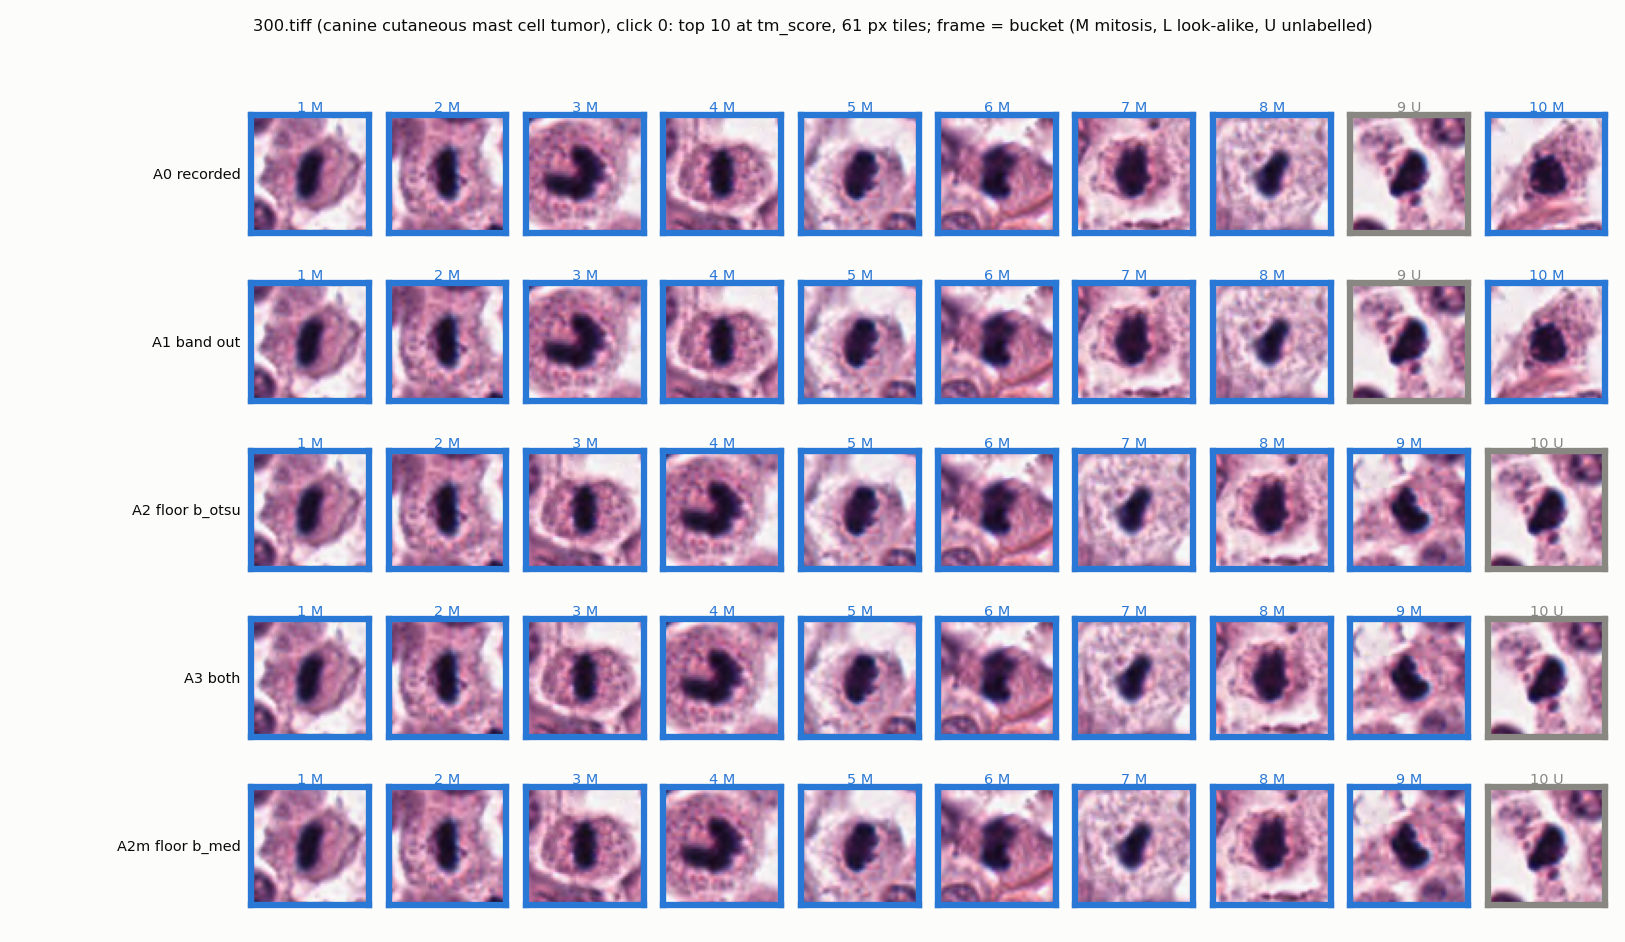

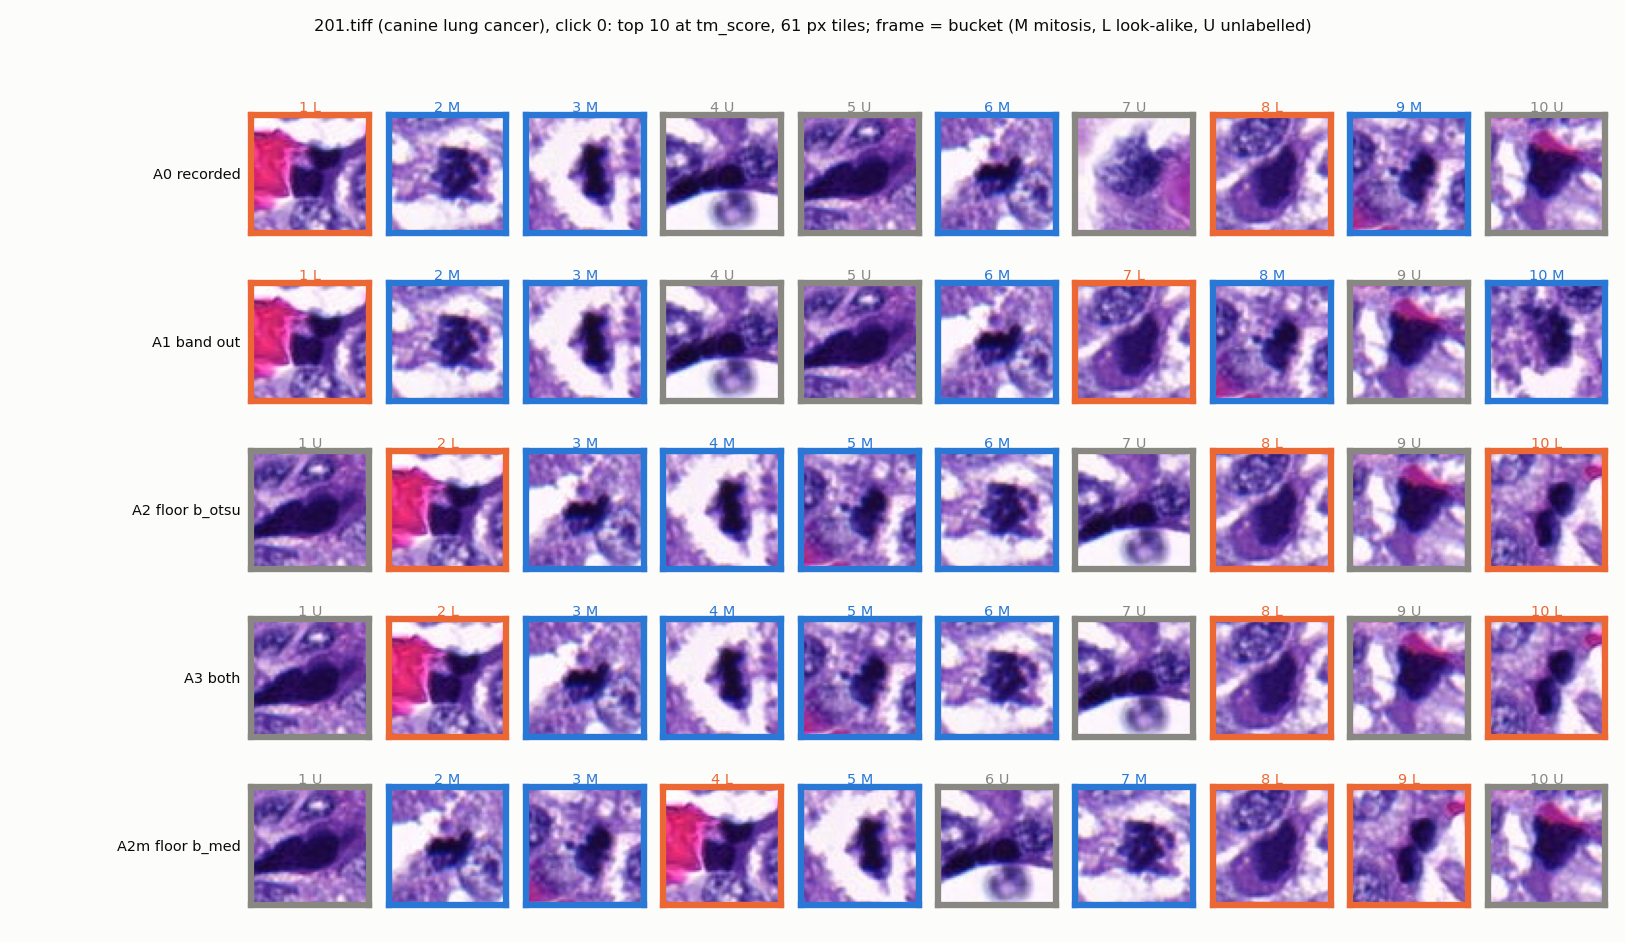

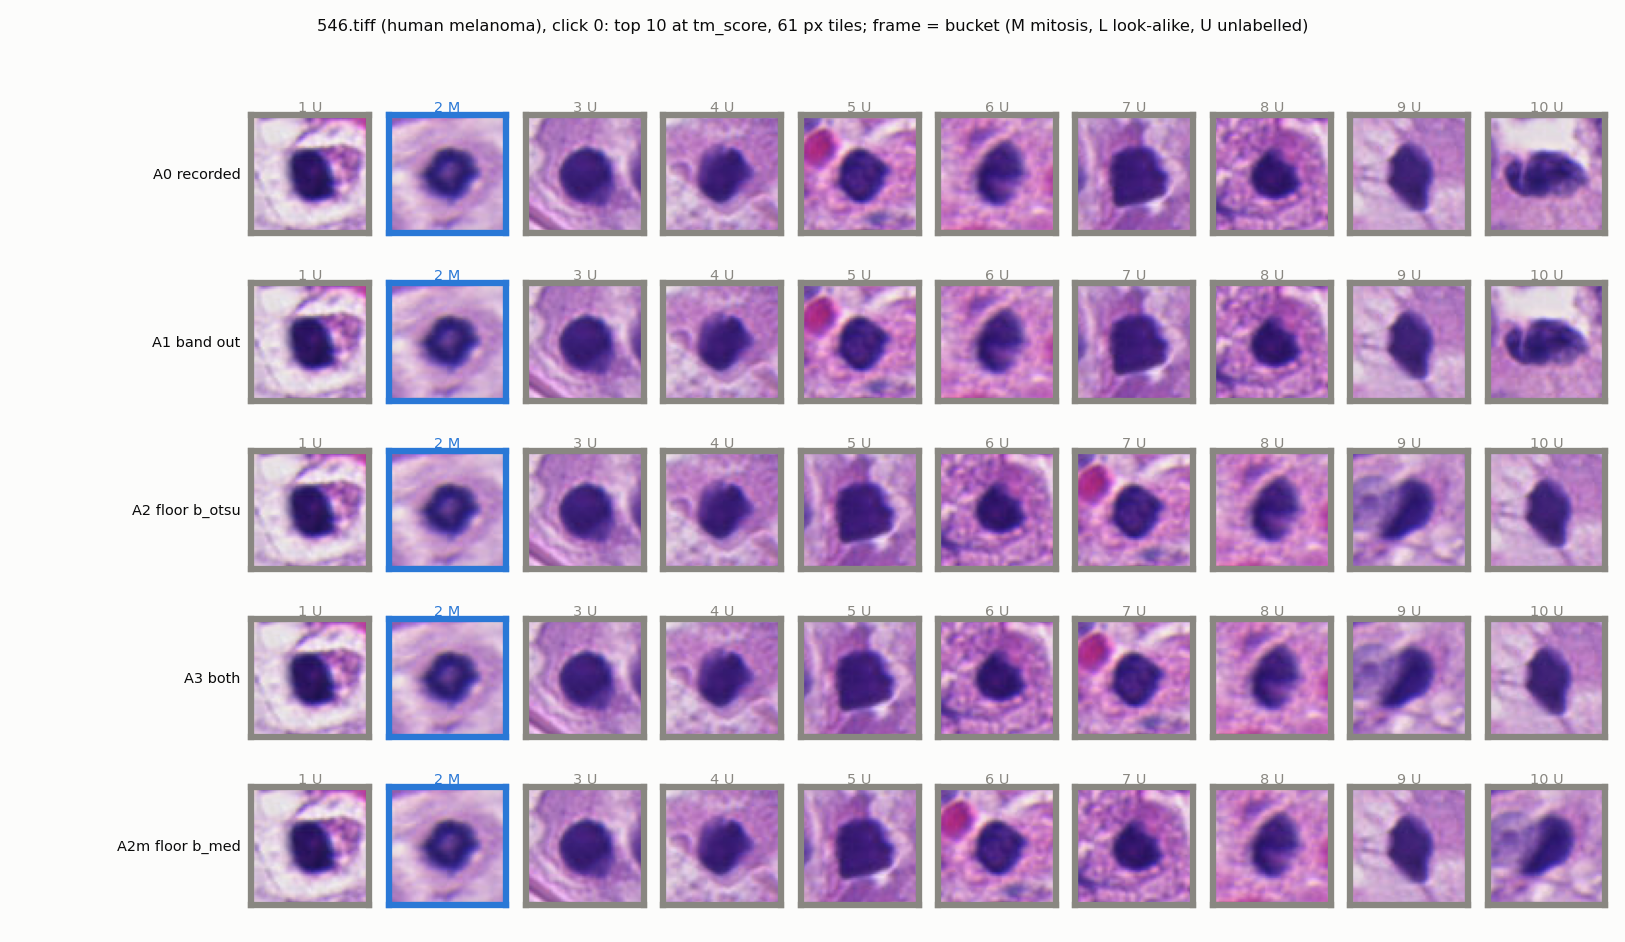

In [17]:
SURFACE, INK, SECONDARY = '#fcfcfb', '#0b0b0b', '#52514e'
LABEL_STYLE = {'mitosis': ('#2a78d6', 'M'), 'look-alike': ('#eb6834', 'L'), 'unlabelled': ('#898781', 'U')}
ARM_LABEL = {'A0': 'A0 recorded', 'A1': 'A1 band out', 'A2': 'A2 floor b_otsu', 'A3': 'A3 both', 'A2m': 'A2m floor b_med'}
written = []
for f in MONTAGE_ROIS:
    if (f, 'A0') not in MONTAGE:
        continue
    fig, axes = plt.subplots(len(MAIN_ARMS), MONTAGE_N, figsize=(MONTAGE_N * 1.25, len(MAIN_ARMS) * 1.45), facecolor=SURFACE)
    for i, arm in enumerate(MAIN_ARMS):
        tiles = MONTAGE[(f, arm)]
        for j in range(MONTAGE_N):
            ax = axes[i, j]
            ax.set_xticks([])
            ax.set_yticks([])
            if j >= len(tiles):
                ax.axis('off')
                continue
            tile, bucket = tiles[j]
            colour, letter = LABEL_STYLE[BUCKET_SHORT[bucket]]
            ax.imshow(tile)
            for sp in ax.spines.values():
                sp.set_edgecolor(colour)
                sp.set_linewidth(3.5)
            ax.set_title(f'{j + 1} {letter}', fontsize=8, color=colour, pad=2)
        axes[i, 0].set_ylabel(ARM_LABEL[arm], fontsize=8, color=INK, rotation=0, ha='right', va='center', labelpad=6)
    dom = DOMAIN_OF[f]
    fig.suptitle(f'{f} ({dom}), click 0: top {MONTAGE_N} at tm_score, 61 px tiles; frame = bucket (M mitosis, L look-alike, U unlabelled)', fontsize=9, color=INK)
    fig.tight_layout(rect=(0.06, 0, 1, 0.96))
    fig.savefig(MONTAGE_PATHS[f], dpi=130, facecolor=SURFACE)
    plt.close(fig)
    written.append(MONTAGE_PATHS[f])
print('montages written:', written)

## Outputs

In [18]:
if SMOKE_ROIS is None:
    existing = [p for p in OUT.values() if os.path.exists(p)]
    assert not existing, f'the full run never overwrites its outputs; these appeared during the run: {existing}'

a0_fill = tm_rows[tm_rows['arm'] == 'A0'].groupby('file_name')['fill_value'].median()
a2_fill = tm_rows[tm_rows['arm'] == 'A2'].groupby('file_name')['fill_value'].median()
FLOORS_OUT = FLOORS.assign(median_clipped_template_fill_otsu=FLOORS['file_name'].map(a2_fill), b_otsu_over_median_fill=FLOORS['b_otsu'] / FLOORS['median_template_fill'], b_med_over_median_fill=FLOORS['b_med'] / FLOORS['median_template_fill'])
EDGE_OUT = EDGE.reset_index().assign(spec_vs_floored_top100_differs=lambda d: d['arm'].map({'A1': leak_n['A1'], 'A3': leak_n['A3']}))
ADV_LOG = pd.DataFrame(list(ADV.values()))[['item', 'concern', 'test', 'result', 'action']]
print('adversarial log:')
print(ADV_LOG.to_string(index=False, max_colwidth=180))
assert (ADV_LOG['result'] != '').all(), f"an adversarial concern has no result: {ADV_LOG.loc[ADV_LOG['result'] == '', 'item'].tolist()}"

PER_RUN.to_csv(OUT['per_run'], index=False)
TOP.to_csv(OUT['top30'], index=False)
PER_ROI.to_csv(OUT['per_roi'], index=False)
DELTA.to_csv(OUT['delta_stats'], index=False)
FLOORS_OUT.to_csv(OUT['floors'], index=False)
EDGE_OUT.to_csv(OUT['edge'], index=False)
WHITE.to_csv(OUT['white'], index=False)
NEARSEED.to_csv(OUT['nearseed'], index=False)
ADV_LOG.to_csv(OUT['adversarial_log'], index=False)
print('\nwritten:', *OUT.values(), sep='\n  ')
print(f'\nDECISION: {DECISION}' + (' [SMOKE RUN: not a result]' if SMOKE_ROIS is not None else ''))
print(f'notebook {(time.time() - NB_T0) / 60:.1f} min')

adversarial log:
                        item                                                                                                                                                                              concern                                                                                                                                                                                 test                                                                                                                                                                               result                                                                                                                           action
          band_dilation_leak valid = False in the band (the spec) removes band peaks, but extract_peaks dilates the whole fused map before applying valid, so a band response can still stop an interior pixel... scratch test before coding (recorded mo_pad61 templates, 337/201/300.tif


written:
  ../../results/tm_border_floor_49roi_6seed_per_run.csv
  ../../results/tm_border_floor_49roi_6seed_top30.csv
  ../../results/tm_border_floor_49roi_6seed_per_roi.csv
  ../../results/tm_border_floor_49roi_6seed_delta_stats.csv
  ../../results/tm_border_floor_49roi_6seed_floors.csv
  ../../results/tm_border_floor_49roi_6seed_edge.csv
  ../../results/tm_border_floor_49roi_6seed_white.csv
  ../../results/tm_border_floor_49roi_6seed_nearseed.csv
  ../../results/tm_border_floor_49roi_6seed_adversarial_log.csv

DECISION: recommend A3 for a DECISIONS entry (all four conditions hold)
notebook 53.1 min


## Reading the result

The full run is 49 ROIs x 6 clicks = 294 clicks x 7 arms, both axes, 53 min. Every number is **in-sample** on the 49
ROIs of `images/extra_valid`, which D5 documents as an optimistic draw.

### Decision-rule outcome

**Recommend `A3` (band out + floor clip at `b_otsu`) for a DECISIONS entry. All four pre-registered conditions hold,
and M3 shows no significant loss.**

| condition | result |
|---|---|
| 1. `A3 - A0` at K = 10, `tm_score`, meets the D5 bar with a positive delta | **+3.71 pts** (P@10 0.542 -> 0.579), CI [+2.48, +5.07], 34 W / 7 L / 8 T of 49 ROIs, Holm p 2.2e-7 |
| 2. no significant loss at any K on either axis | `tm_score`: +3.71 / +2.99 / +2.54 at K = 10/20/30. `chromatin_od`: +1.80 / +0.97 / +0.78. No loss anywhere. |
| 3. M1 holds | 0 boundary detections on all four band arms; `A0` has exactly the recorded 252 |
| 4. M2 falls | white-adjacent share of top-10 non-mitoses 0.239 -> 0.194, CI of the difference [-0.064, -0.029] |

**What this recommendation is and is not.**
- **Almost all of the gain is the clip.** `A2 - A0` = +3.20 pts. The band alone gives `A1 - A0` = +0.41 pts at
  `tm_score`, not significant (Holm 0.25).
- **The band earns its place on the second axis and on M1.** At `chromatin_od`, `A1 - A0` = +2.28 pts at K = 10,
  Holm 3e-4. The od window is replicate-padded too, and `A0`'s od top 10 holds 174 band entries, 76 % of them
  unlabelled. It misses the D5 bar only on the majority clause (20 W / 2 L / 27 T).
- **Adoption needs a dated amendment to D3.** D3 forbids a rescale, stretch or top clip, and as written it does not
  cover a bottom clip (cell 0). Adopting one changes the search channel, so it needs a dated amendment.

### Read this first: what contradicts the mechanism story

1. **The clip's gain does not track white.** The mechanism predicts the gain lives where glass and lumen are.
   - Spearman over ROIs of the per-ROI `A2 - A0` TP@10 delta: against the ROI's white share +0.08 (p 0.60); against
     the share of pixels clipped -0.26 (p 0.08).
   - By domain, the largest gains are in canine lymphosarcoma (+6.9 pts, white share 3.9 %) and neuroendocrine
     (+5.7, 15 %).
   - The smallest are in melanoma (+1.7, 1.6 %) and mast cell tumour (+2.1, **21.5 %, the whitest domain**).
   - **In aggregate the story partly holds.** Of the net reduction in top-10 false positives (1347 -> 1238, -109),
     82 are white-adjacent (322 -> 240).
   - **But the clip also reshuffles the top 10.** 1193 of 2940 top-10 slots change: 560 mitoses leave and 669 enter.
     That is not a targeted removal of white-adjacent false positives.
   - **The ROI-level effect is not concentrated in white tissue.** The most likely reading is below, under "What the
     floor actually is". It is an interpretation, not a measured cause.
2. **The floor is not a glass floor.**
   - **Where `b_otsu` sits.** It lies at or above the click's own template fill value on **156 of 294 clicks**
     (median `b_otsu / fill` 1.03, range 0.47-3.33).
   - **How much it clips.** More than 60 % of pixels on **20 of 49 ROIs**: `322`, `337`, `339`, `343`, `242`, `460`,
     `410`, `462`, `013`, `007`, `100`, `123`, `128`, `529`, `527`, `546`, `549`, `403`, `364` and `401`.
   - **What the flagged ROIs look like** (thumbnails of 337, 529 and 401).
     - The bottom class is not glass. It is everything that is not a nucleus: cytoplasm, collagen and retraction
       spaces.
     - 337 is a dense round-cell mast cell tumour, and 529 a dense epithelioid melanoma with almost no glass (white
       1 %).
     - `hem_c` on these is nuclei on a flat floor.
     - 401 is a biopsy fragment on 55 % glass, where the clip takes glass and stroma together.
   - **The template changes as well as the image.** Its fill rises (clipped / recorded median 1.30, max 3.40), and its
     mass weight falls (median 0.89).
   - **The level hardly matters.** `A2m` (the median floor) is indistinguishable from `A2` on every K and axis (all
     Holm p >= 0.21).
3. **The border demonstration fails as specified (M5 b).** For the ringed `mo_pad61` template, a disc bisected by the
   edge peaks on the boundary row but scores only **0.87x** the same disc 60 px inside. The replicated streak darkens
   the template's ring as well as its box.
   - The post-smoke descriptive rows show what replication does instead. Against a constant tissue-level pad, it
     raises the score of the bisected disc 1.41x, and of a disc centred 6 px outside the ROI 2.04x.
   - So replication makes a cut object score like a whole one; it does not let it out-score one. That fits M1's
     enrichment (252 boundary-row detections) and the small `tm_score` effect of fix 1.
4. **M4 has nothing to measure.**
   - On every arm, the whole 29,000-detection pool holds only 2 or 3 near-seed non-TP detections (1-2 match radii from
     the click), and 0 in any top 30.
   - The D11 blank's white fill does raise a neighbour's score in the synthetic case (M5 c: 1.181 -> 1.328 with the
     square at the ROI minimum, 1.173 at `b`).
   - But with the 51 px blank and the 61 px template, no such neighbour reaches a pool. The prediction that the floor
     reduces near-seed leaks can be neither confirmed nor refuted.

### M1 to M5

| check | result | holds? |
|---|---|---|
| M1 boundary-row detections (`edge_px == 0`, whole pools) | A0 252, A1 0, A1v 0, A2 254, A3 0, A3v 0, A2m 247. `edge_px < 30`: A0 766, band arms 0 | **yes** |
| M2 white-adjacent share of top-10 non-mitoses, `tm_score` | A0 0.239. A3 0.194 [-0.064, -0.029]; A2 0.194 [-0.063, -0.029]; A2m 0.205 [-0.058, -0.014]; A1 0.237 [-0.009, +0.003]. At `chromatin_od`, A3 - A0 = -0.002 [-0.016, +0.011] | **falls** at `tm_score`; flat at od |
| M3 white-adjacent mitoses in the top 30, `tm_score` | A0 362. A3 354 (-8; 3 W / 5 L / 41 T; Holm p 0.70; CI of total [-24, +4]); A2 355 (-7; Holm 0.70). At od, A3 - A0 = -2 | **no significant loss** |
| M4 near-seed non-TP leaks, `tm_score` | pool totals 2-3 on every arm; 0 in every top 30 | **untestable** |
| M5 (a) white half-plane | A0 beside/uniform 1.038 (gap 30 px), 1.149 (gap 20). Clip 1.000. Pre-registered **PASS** | trivially: tissue `t` (0.0253) < `b` (0.0272) |
| M5 (b) border streak | boundary peak at y = 0 but 0.875x the interior disc; band-floored: 0 detections within 30 px. Pre-registered **FAIL** | see contradiction 3 |
| M5 (c) blank fill | disc 20 px from the blank: no square 1.181, ROI-minimum fill 1.328 (+12 %), `b` fill 1.173 | the fill mechanism is real |

**The M5 (a) PASS is trivial.** On `300.tiff` the pre-registered tissue level lies below `b`, so the tissue and the
glass both clip to `b`.
- On tissue that stays above `b` (post-smoke row, `t` = 0.0501), the clip leaves 27 % of A0's white excess at a
  30 px gap and 36 % at 20 px.
- The analytic `(t - b) / (t - glass)` predicts 48 %.

So where tissue is lighter than glass by more than `b`, the clip bounds the white reward but does not remove it.

### Primary and secondary tables

Pooled precision deltas in points. W/L/T are over 49 ROIs. Holm runs within the family. The full table, including
`ci_low`, `ci_high`, the t interval and the exact p, is in `delta_stats.csv`.

| family | axis | contrast | K = 10 | K = 20 | K = 30 | D5 bar at K = 10 |
|---|---|---|---|---|---|---|
| **primary** | tm | **A3 - A0** | **+3.71** (34/7/8, Holm 2e-7) | +2.99 (38/7/4, 2e-8) | +2.54 (39/5/5, 3e-8) | **met** |
| tm_decomposition | tm | A1 - A0 | +0.41 (11/3/35, 0.25) | +0.37 (0.15) | +0.24 (0.25) | no |
| | tm | A2 - A0 | +3.20 (31/7/11, 3e-5) | +2.84 (1e-7) | +2.32 (1e-6) | met |
| | tm | A3 - A1 | +3.30 (32/6/11, 8e-6) | +2.62 (5e-7) | +2.30 (2e-6) | met |
| | tm | A3 - A2 | +0.51 (8/2/39, 0.23) | +0.15 (0.47) | +0.22 (0.28) | no |
| od_five | od | A3 - A0 | +1.80 (23/8/18, 0.042) | +0.97 (0.12) | +0.78 (0.14) | no (majority) |
| | od | A1 - A0 | +2.28 (20/2/27, 3e-4) | +0.88 (0.040) | +0.69 (0.003) | no (majority) |
| | od | A2 - A0 | -0.34 (8/13/28, 1) | +0.05 (1) | +0.08 (1) | no |
| | od | A3 - A1 | -0.48 (9/14/26, 1) | +0.09 (1) | +0.09 (1) | no |
| | od | A3 - A2 | +2.14 (16/2/31, 0.003) | +0.92 (0.073) | +0.70 (0.068) | no |
| median_floor | tm | A2m - A2 | +0.03 (1) | -0.24 (1) | 0.00 (1) | no |
| | od | A2m - A2 | -0.14 (1) | -0.29 (1) | -0.02 (1) | no |
| descriptive | tm | A1 - A1v | +0.03 | +0.09 | +0.03 | - |
| | tm | A3 - A3v | +0.07 | +0.07 | +0.08 | - |
| | tm | A2m - A0 | +3.23 | +2.60 | +2.32 | - |

**The two fixes add.** At K = 10 the additivity gap `(A3 - A0) - (A1 - A0) - (A2 - A0)` is +0.10 pts, and `A3 - A1`
(+3.30) is close to `A2 - A0` (+3.20).

**The clip and the band split by axis.** The clip helps `tm_score` but not chromatin od (`A2 - A0` at od is -0.34 pts
at K = 10). The band acts mostly on od.

This is **not** simply "od sees the pool set, not its order". The clip changes the pool set a lot:
- **What leaves A0's pool:** about 2,520 mitoses and 10,310 non-mitoses.
- **What enters A2's pool:** 2,960 mitoses and 9,790 non-mitoses (net +436 mitoses).
- **Where the entrants land on od:** 631 entering mitoses reach od's top 10, but so do 571 entering non-mitoses.
  Leaving it were 604 mitoses and 507 non-mitoses.

The extra pool mitoses therefore do not reach od's top 10 on net (post-run check on the search pickle).

**The generator grows.** Mitoses in the whole pool (83-100 detections per click), matched in `tm_score` order:
- `A0` 24.67 per click;
- `A3` 26.21 per click, +1.54, 44 W / 4 L / 1 T, exact p 4e-10;
- `A2` 26.15 per click;
- `A1` 24.68 per click, +0.01.

The clip therefore puts more mitoses into the 100-peak pool, as well as ordering them better.

**Robustness.** The largest single-ROI gain is `291.tiff` (+13 TP over 6 clicks, 12 % of the +109 total). Without it,
the pooled K = 10 gain is still +3.33 pts. Per-click spread does not grow: the mean within-ROI SD of TP@10 is 1.03
(A0) and 0.99 (A3). The worst click per ROI improves (mean worst TP@10 4.06 -> 4.55). The four ROIs whose worst click
finds 0 stay at four.

### Per domain (`tm_score`, P@10; 7 ROIs each; W/L/T at K = 10)

| domain | clip share | white share | A0 | A1 | A2 | A3 | A2m | A3 - A0 | W/L/T |
|---|---|---|---|---|---|---|---|---|---|
| **canine cutaneous mast cell tumour** | 0.64 | 0.215 | 0.648 | 0.652 | 0.664 | 0.669 | 0.660 | +2.1 | 5/1/1 |
| **canine lung cancer** | 0.50 | 0.073 | 0.376 | 0.374 | 0.419 | 0.417 | 0.421 | +4.0 | 4/1/2 |
| canine lymphosarcoma | 0.39 | 0.039 | 0.605 | 0.605 | 0.664 | 0.674 | 0.674 | +6.9 | 6/1/0 |
| canine soft tissue sarcoma | 0.55 | 0.040 | 0.576 | 0.579 | 0.607 | 0.610 | 0.605 | +3.3 | 5/1/1 |
| human breast cancer | 0.65 | 0.096 | 0.631 | 0.636 | 0.650 | 0.652 | 0.650 | +2.1 | 4/2/1 |
| human melanoma | 0.56 | 0.016 | 0.393 | 0.395 | 0.402 | 0.410 | 0.410 | +1.7 | 4/1/2 |
| human neuroendocrine | 0.59 | 0.154 | 0.564 | 0.581 | 0.610 | 0.621 | 0.600 | +5.7 | 6/0/1 |

**A3 - A0 is positive in direction in every domain.** No domain-level test was pre-registered, and n = 7 per domain
resolves nothing on its own.

**Mast cell tumour**, the domain the white-surround story was built on (82 % of its top-10 non-mitoses were
white-adjacent), gains among the least. **Lung** gains +4.0.

At `chromatin_od`, `A3 - A0` ranges from -0.5 (melanoma) to +6.0 (neuroendocrine), and nearly all of it comes from
the band.

### Montages (click 0, top 10 at `tm_score`)

- **`300.tiff`, mast cell.**
  - A0 and A1 have identical top 10s: 9 mitoses and 1 unlabelled, a dark round nucleus beside retraction spaces, at
    rank 9.
  - A2, A3 and A2m share one top 10. A new mitosis enters, and that same white-bordered nucleus drops to rank 10.
    The clip demotes it but does not remove it.
- **`201.tiff`, lung.**
  - A0 has 4 mitoses. Its false positives are a dark nucleus against bright eosinophilic material (a look-alike, at
    rank 1), elongated hyperchromatic nuclei, a nucleus over a capillary, and look-alikes.
  - A1 reorders the same set and gains one mitosis (5).
  - A2, A3 and A2m still have 4 mitoses. The elongated dark nucleus rises to rank 1, and a two-nucleus look-alike
    enters. Under the clip, the false positives are dense dark nuclei, not white-adjacent ones.
- **`546.tiff`, melanoma (stuck).**
  - Every arm has 1 mitosis (rank 2). The false positives are large, round, hyperchromatic interphase melanoma
    nuclei.
  - The clip swaps one white-bordered candidate for another dense nucleus. The composition does not change.
  - This ROI's problem is shape and texture, not the surround, and no change at the TM step reaches it.

### Adversarial log

The full log is in `results/tm_border_floor_49roi_6seed_adversarial_log.csv`.

| item | result | action |
|---|---|---|
| band dilation leak | real: the spec version differs from the floored one in its top-100 pre-NMS set and post-NMS pool on 68/294 clicks (A3: 67), but changes TP@K by at most +0.09 pts | `A1`/`A3` floor the band; `A1v`/`A3v` reported |
| threshold shift | threshold mean -0.956 (A0) vs -0.595 (A2), but MAX_PEAKS = 100 binds on **every** click of every arm | the threshold decides nothing; the clip changes which 100 peaks enter NMS |
| dense tissue null | refuted in the predicted direction: the gain does not shrink where little is clipped (Spearman -0.26 with clip share, +0.08 with white share) | contradiction 1 |
| floor is a scanner floor | `b_otsu` CV within a domain 0.14 (mast cell) to 0.44 (neuroendocrine); scanner not in MIDOG++.json | per ROI by design; no within-ROI ranking crosses ROIs |
| band changes robust stats | A1/A0 median ratio 1.004 (0.94-1.03), MAD 1.001 (1.00-1.14) | negligible, and the threshold does not bind anyway |
| fix interaction | additive: gap +0.10 pts at K = 10 | - |
| floor above template fill | 156/294 clicks; clipped fill x1.30, mass weight x0.89; 2 clipped templates with mass weight <= 0 (A0 itself has 3) | contradiction 2 |
| blank fill needs `hem.min() < b` | holds on all 49 ROIs (every `hem.min()` is 0.0000); fill = `b` asserted per click | - |
| M5 tissue level | the pre-registered `t` lies below `b` on `300.tiff`, so (a) passes trivially | post-smoke `t_above_b` row added, descriptive |
| band mitoses unreachable | 28/2782 annotated mitoses (1.0 %) within 30 px of the edge; A0 had 17 band mitoses in its `tm_score` top 10s (75 band slots in all) | a benchmark correction, not netted out |
| Otsu clips most pixels | 20/49 ROIs over 60 % | contradiction 2 |
| lumen TP loss | no significant loss (Holm 0.70) | - |
| self-matches | 0 in every list, both axes, all arms | no rerun |
| 2 px band count | A0: `edge_px == 0` 252, `edge_px <= 2` **273** | the prompt's 273 is `<= 2` and its 252 is `== 0`; both reproduce |

*Post-run patch.* The executed output of the gate-8/M1 cell, and the first-written
`adversarial_log.csv`, said "the prompt's 273 matches neither exactly". That string was hard-coded before the run and
is wrong. The cell source and that one CSV row were corrected after the run; no number changed.

### What I changed in the prompt, and why

1. **Fix 1 is implemented as band invalid and floored, not invalid alone.**
   - Why: `extract_peaks`' max filter reads the whole fused map, so band scores still suppressed interior peaks at
     `edge_px` 30-36.
   - Evidence: found in a scratch test before coding, and confirmed in the run (68 clicks differ).
   - The prompt's version runs as `A1v` and `A3v`. The two are within 0.1 pt everywhere, so the decision does not
     depend on this choice.
2. **Each floor shares one correlation across its arms.** Each click runs three correlations, not five. This is exact,
   and it is asserted on the first click of every ROI against the verbatim `search_once` (`A0`) and against fresh,
   independent `A1` and `A3` searches.
3. **The M5 levels and the peak window were fixed in cell 0.** Tissue `t` is the median non-white `hem`, glass is the
   median white `hem`, the disc sits at `m_keep`, and the peak is the max within 15 px. Post-smoke descriptive rows
   were added after the smoke run and are labelled as such: `t_above_b`, and the constant-pad comparators (b2, b3).
4. **The pre-registration settles what the prompt left open:**
   - "significant loss" (Holm < 0.05 with a negative pooled delta);
   - the family sizes (3 / 12 / 15 / 6);
   - M2's decision contrast (`A3 - A0`), and M3's Holm over two contrasts;
   - M4's scope (Euclidean distance; pool, top 30, top 10).

### What I could not check

- **Generalisation.** Every number is in-sample on 49 ROIs and the recorded clicks; there is no held-out set.
- **Why the clip helps where there is no glass.** Gains on lymphosarcoma and melanoma, where the white share is
  1-4 %, are not explained by the white-surround mechanism.
  - The likely mechanism is that the floor flattens cytoplasm and stroma as well as glass. That bounds the ring term
    for every light surround, and it also lowers the template's mass weight.
  - That is an interpretation. Separating the image-side clip from the template-side change, for example by clipping
    the image but cutting the template from `hem`, was not in this prompt.
- **M4's prediction.** Near-seed leaks barely exist for `mo_pad61`, so the floor's effect on them cannot be measured.
- **The scanner.** MIDOG++.json carries no scanner field, so the floor's stability is reported per domain only.
- **The product.** Fix 1 is a benchmark correction, since the product has no ROI border. Its value in the product is
  only what the od axis gains here, and it costs 1 % of annotated mitoses in this benchmark.
- **The next candidate, if the clip is judged insufficient:** a tissue-masked ring via the shape-plus-mass
  decomposition. It is named, not built.